# Código Cristalizador SQM
### ¿Qué tiene que resolver el código?

Un cristalizador evaporativo MSMPR se describe con tres balances acoplados:

- Balance de población (PBE): cómo cambia la distribución de tamaños n(L,t) por crecimiento, nucleación y descarga del producto. Es una EDP. Al dividir el eje de tamaños en celdas (volúmenes finitos) se convierte en un sistema de EDOs.
- Balance de masa de soluto y de solvente: el KNO₃ que pasa de la solución al cristal, y el agua que sale como vapor. Aquí entra la evaporación.
- Balance de energía: el calor que se entrega, el que se va en evaporar agua y el calor de cristalización.

En resumen: un sistema grande de EDOs, propiedades termodinámicas (solubilidad, presión de vapor, calor latente), datos de planta para comparar y gráficos. 

### Organización del notebook

Las secciones siguen el **mismo orden que la checklist de requisitos** del modelo. Cada sección cierra con una tabla del estado de los ítems correspondientes.

| Sección | Ítem de la checklist |
|---|---|
| 1 | Configuración central y datos de planta (entradas del modelo) |
| 2 | Termodinámica del KNO₃ |
| 3 | Solubilidad del perclorato e interacción con el magnesio |
| 4 | Modo evaporativo (flash al vacío) |
| 5 | Balances |
| 6 | Cinética y balance de población |
| 7 | Factor de forma (forma granular) |
| 8 | Incorporación del perclorato en el cristal |
| 9 | Equipo y control |
| 10 | Calibración y verificación (incluye sensibilidades y frente de Pareto) |
| 11 | Integración y documentación |

Este notebook reúne y mejora lo que estaba en `Evaporative_MSMPR_DPBE-2.ipynb` (evaporación, disolución, perclorato por tamaño, escalones) y en `MSMPR_KNO3_DPBE_sensibilidad_Pareto.ipynb` (sensibilidades, elasticidades, frente de Pareto, malla doble, exportación de resultados).

**Cómo ejecutarlo:** *Restart & Run All*. La ejecución completa toma unos minutos; las secciones 9 y 10 concentran las simulaciones repetidas.

### Librerías

In [1]:
# =========================================================
# 0. Librerías
# =========================================================
# Biblioteca estándar
from dataclasses import dataclass, field   # parámetros ordenados y con nombre
import copy                                 # duplicar casos para sensibilidad
import os, time, datetime                   # tiempos de cómputo y carpeta de resultados

# Cálculo numérico
import numpy as np                          # vectores: n(L), flujos, momentos
from scipy.integrate import solve_ivp       # integrador de EDOs (rígido: BDF/LSODA)
from scipy.optimize import brentq, least_squares  # ec. algebraicas y ajuste de parámetros
from scipy.sparse import lil_matrix         # patrón del jacobiano para el integrador

# Datos y gráficos
import pandas as pd                         # lectura de los Excel de SQM (requiere openpyxl)
import matplotlib.pyplot as plt             # CSD, trayectorias, diagnósticos

# Verificación rápida de versiones (útil para reproducibilidad del informe)
import scipy, matplotlib
print("numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

numpy 1.26.0 | scipy 1.16.3 | pandas 3.0.1 | matplotlib 3.10.8


## 1. Configuración central y datos de planta

Todos los valores que el modelo usa como entrada están **en esta sección** y en ningún otro lugar: alimentación, temperaturas, tiempos de residencia, propiedades, forma del cristal, parámetros cinéticos y de perclorato, y la malla de tamaños. Las secciones siguientes solo los leen. Para cambiar un caso se modifica esta sección (o se copia `OPER` y se cambia la copia, como en los análisis de sensibilidad). Cada valor lleva su fuente; los supuestos del equipo están marcados como tales.

| Variable | Valor | Fuente |
|---|---|---|
| Alimentación a A3110 | 378,18 t/h de SSK + licor, más 27,14 t/h de **agua de dilución** (variable manipulable) | Balance de masa detallado v6 |
| Temperatura de alimentación | 70 °C | Informe de parámetros, corriente 334 SSK-d |
| T de A3110 / A3210 | 55 °C / 40 °C | SQM, «Sistema de cristalización al vacío — Área 3000» (jul-2026) |
| Tiempo de residencia A3110 / A3210 | 0,7 h / 1,4 h | Protocolo experimental, Entrega 2 (supuesto del equipo) |
| Fracción de agua del SSKd | 0,3994 kg/kg | Informe de parámetros, corriente 334 SSK-d |
| Densidad del SSKd | 1518 kg/m³ | Informe de parámetros, corriente 334 SSK-d |
| Cp del licor | 2248 J/(kg·K) | Informe de parámetros, corriente 334 SSK-d |
| Densidad del licor en el cristalizador | 1470 kg/m³ | PFD GEA (repositorio, `params.py`) |
| Densidad del cristal de KNO₃ | 2110 kg/m³ | Perry, Tabla 2-1 |
| Cp del KNO₃ sólido | ≈ 950 J/(kg·K) | NIST Chemistry WebBook (≈ 96 J/(mol·K) a 25 °C); verificar |
| ΔH de cristalización del KNO₃ | −7,73 kcal/mol | SQM (jul-2026) |
| Calor latente del agua | λ(T) ≈ 2501 − 2,361·T [kJ/kg] | Aproximación lineal; error < 0,1 % frente a IAPWS entre 40 y 55 °C |
| Presión de vacío A3110 / A3210 | 11,59 kPa / 5,43 kPa | DWSIM, Entrega 2 (BPE resultante ≈ 6,2 °C / 5,6 °C) |

In [2]:
# =========================================================
# 1.1 Constantes, caso base de operación y propiedades
# =========================================================
R_GAS = 8.314            # J/(mol K)
M = {"KNO3": 101.10, "KClO4": 138.55, "K": 39.10, "NO3": 62.00,
     "ClO4": 99.45, "Mg": 24.305, "Na": 22.99, "NaNO3": 84.99}   # g/mol

OPER = {
    "F_pre_kg_s": 378.18 * 1000 / 3600,     # SSK + licor antes del agua de dilución (balance v6)
    "F_dil_kg_s": 27.14 * 1000 / 3600,      # agua de dilución: VARIABLE MANIPULABLE (balance v6)
    "T_feed_C": 70.0,
    "T_C":   {1: 55.0, 2: 40.0},            # A3110, A3210 (fijadas por el vacío)
    "tau_h": {1: 0.7,  2: 1.4},             # inventario / flujo de entrada (Entrega 2)
    "P_kPa": {1: 11.59, 2: 5.43},           # solo para informar el vacío
    "siembra_alim": 0.0,                    # fracción másica de cristales en la alimentación (0 = licor claro)
}
OPER_BASE = copy.deepcopy(OPER)             # referencia para los análisis de sensibilidad

PROP = {
    "x_agua_SSKd": 0.3994, "rho_SSKd": 1518.0, "rho_liq": 1470.0, "rho_c": 2110.0,
    "cp_liq": 2248.0, "cp_c": 950.0,
    "dHc_J_kg": 7.73 * 4184.0 / (M["KNO3"] / 1000),     # calor liberado al cristalizar [J/kg KNO3]
}
def lambda_agua(T_C):
    """Calor latente de vaporización del agua [J/kg] (aprox. lineal, 0-100 °C)."""
    return (2501.0 - 2.361 * T_C) * 1e3

def tsat_agua(P_kPa):
    """T de saturación del agua pura [°C] (Antoine)."""
    return 1730.63 / (8.07131 - np.log10(P_kPa / 0.133322)) - 233.426

### 1.2 Granulometría de planta (referencia de calibración)

Tamizajes de los under de A3110 y A3210 (`Compilado cristalizadores NPT3.xlsx`, hojas AG, 15 al 31 de agosto de 2026): **21 tamizajes por equipo**. Se usa el **promedio del pasante acumulado en masa** por malla, con su desviación estándar como incertidumbre. El D50 que resulta (≈ 560 µm en A3110 y ≈ 520 µm en A3210) es consistente con el informe de seguimiento (541 y 514 µm).

Un tamiz deja pasar un cristal según su **dimensión menor**. Para cristales equidimensionales (granulares), todas las dimensiones son parecidas, así que la abertura de malla es directamente la longitud característica $L$ del modelo (sección 7).

In [3]:
MALLAS_UM = np.array([38, 53, 75, 106, 250, 500, 850, 2000.])
AG_PLANTA = {   # pasante acumulado [% masa]: promedio y desviación estándar de 21 tamizajes por equipo
    1: {"media": np.array([0.13, 0.31, 0.79, 4.77, 14.21, 43.06, 84.36, 97.52]),
        "sd":    np.array([0.12, 0.29, 0.59, 3.24, 5.73, 8.22, 5.13, 3.94])},
    2: {"media": np.array([0.15, 0.34, 0.77, 4.71, 14.47, 48.02, 84.27, 98.30]),
        "sd":    np.array([0.14, 0.31, 0.58, 3.18, 6.49, 6.27, 5.05, 2.94])},
}
def d_pct(mallas, pasante, q):
    """Tamaño [µm] al q % pasante (interpolación en log del tamaño)."""
    return float(np.exp(np.interp(q, pasante, np.log(mallas))))

for k, nombre in ((1, "A3110"), (2, "A3210")):
    m = AG_PLANTA[k]["media"]
    print(f"{nombre}: D10 = {d_pct(MALLAS_UM, m, 10):.0f} µm, D50 = {d_pct(MALLAS_UM, m, 50):.0f} µm, "
          f"D80 = {d_pct(MALLAS_UM, m, 80):.0f} µm, finos < 106 µm = {m[3]:.1f} %")

A3110: D10 = 171 µm, D50 = 547 µm, D80 = 804 µm, finos < 106 µm = 4.8 %
A3210: D10 = 169 µm, D50 = 515 µm, D80 = 798 µm, finos < 106 µm = 4.7 %


### 1.3 Datos históricos de laboratorio (calidad)

Estadísticas de laboratorio de SQM (`Base de datos.xlsx`, histórico 2025–2026) y del balance v6, recopiladas en el repositorio (`msmpr_core/params.py`). Se usan para **anclar y validar** el perclorato y la composición del licor madre (sección 8).

In [4]:
HIST = {
    "MLK_ClO4_g_L": 3.60, "MLK_Mg_g_L": 31.0,          # medianas licor madre (MLK)
    "crudo_ClO4_ppm": 202.0, "crudo_ClO4_p25_p75": (136.0, 432.75),   # KNO3 crudo (corriente 17)
    "refinado_ClO4_ppm": 21.0, "refinado_ClO4_p25_p75": (20.0, 36.0),  # KNO3 refinado (área 6000)
    "h_licor_crudo": 0.070,      # kg licor equivalente / kg crudo (balance v6: w_H2O crudo / w_H2O MLK)
    "eta_refinacion": 0.899,     # remoción de ClO4 en el área 6000 (Compilado pruebas A6000)
    "KPI_refinado_ppm": 40.0,
}

### 1.4 Malla de tamaños, forma del cristal y parámetros del modelo

- **Malla:** geométrica entre 5 µm y 3 mm, 180 clases. El esquema upwind es de primer orden y tiene difusión numérica: con 90 clases el D50 cambiaba 4 % al duplicar la malla; con 180 cambia ~2 % (prueba de malla doble, sección 10). `set_malla()` permite cambiar el número de clases.
- **Forma base:** granular, $k_v = \pi/6$, $\psi = 1$. Se justifica en la sección 7.
- **Cinética:** $\theta = \log_{10}(k_{bs}/k_g^2)$ calibrado con la granulometría de planta. El valor guardado aquí es el que entrega la sección 10; si se recalibra, se actualiza esta celda.
- **Perclorato:** $k_{inc}$ se estima en la sección 8 a partir del histórico de crudo y del MLK; el resto son placeholders.

In [5]:
def set_malla(n=90):
    """Define (o redefine) la malla de tamaños y todas las variables que dependen de ella."""
    global NCLASES, EDGES, DL, LC, L3, L2, NEST, H_CLAS, JAC_SP
    NCLASES = n
    EDGES = np.concatenate([[0.0], np.geomspace(5e-6, 3e-3, n)])
    DL = np.diff(EDGES); LC = 0.5 * (EDGES[1:] + EDGES[:-1])
    L3 = (EDGES[1:]**4 - EDGES[:-1]**4) / (4 * DL)      # promedio de L^3 en la celda
    L2 = (EDGES[1:]**3 - EDGES[:-1]**3) / (3 * DL)      # promedio de L^2 en la celda
    NEST = NESP + 2 * n                                  # W, K, NO3, ClO4, Mg, I, P + N_i + z_i
    H_CLAS = np.ones(n)                                  # clasificación de descarga (1 = MSMPR)
    S = lil_matrix((2 * NEST, 2 * NEST)); S[:NEST, :NEST] = 1; S[NEST:, :] = 1
    JAC_SP = S.tocsr()                                   # etapa 2 depende de la 1; la 1 no de la 2

NESP = 7
set_malla(180)

FORMA = {"tipo": "granular", "kv": np.pi / 6, "psi": 1.0}
FORMA["ka"] = 6.0 * FORMA["kv"] / FORMA["psi"]           # ver sección 7

KG_REF = 1e-5            # [m/s] fija solo el nivel de sigma (no identificable con la CSD; sección 10)
THETA_CAL = 19.058       # log10(kbs/kg^2) calibrado en la sección 10 (forma granular, 180 clases)
KIN = {
    "kg": KG_REF, "g": 1.0, "Eg": 0.0, "Tref": 40.0, "gamma": 0.0,     # gamma = 0: calibrado (sección 10)
    "kbp": 1e3, "bp": 5.0,                                              # primaria: placeholder
    "kbs": 10 ** THETA_CAL * KG_REF ** 2, "bs": 2.0, "j": 1.0,          # secundaria
    "kdis": 1e-6,                                                       # disolución: placeholder
}
IMP = {
    "k0": 2e-3, "delta_D": 2e4,          # Burton-Prim-Slichter: placeholders
    "kinc": 1e-2, "Gref": 1e-8, "n": 1.0, # inclusiones: kinc se ancla al histórico en la sección 8
    "kp_KClO4": 1e-4,                    # [mol/(kg agua·s)] coprecipitación rápida una vez nucleado
    "sigmaZM_KClO4": None,               # zona metaestable del KClO4: se infiere del histórico en la sección 8
    "pelicula_m": None,                  # espesor equivalente de licor retenido (se ancla en la sección 8)
}

## 2. Termodinámica del KNO₃

Esta sección y la siguiente definen **todo lo que el resto del modelo necesita saber del equilibrio sólido–líquido**. El resto del código (balances, PBE, perclorato) solo llama a las funciones que se definen aquí, así que la sobresaturación queda definida **en un único lugar**.

**Ruta de cálculo (paso a paso):**

1. Curva de solubilidad del KNO₃ en **agua pura**, ajustada a datos de bibliografía con la ecuación de Apelblat.
2. Producto de solubilidad aparente, $K'_{sp}(T) = m_{sat}(T)^2$ (sal 1:1).
3. Extensión a la salmuera con **efecto de ion común** y un **factor de actividad** $\Gamma$.
4. Sobresaturación única para KNO₃ y KClO₄.
5. Composición del licor de SQM en base de agua.

**Convención de unidades.** Las concentraciones se expresan en **molalidad** (mol por kg de agua). Es la base natural para un cristalizador evaporativo: al evaporar agua, la molalidad de las especies que no cristalizan sube en proporción directa, sin depender de la densidad del licor.

In [6]:
# =========================================================
# 2.1 Solubilidad del KNO3 en agua pura (bibliografía)
# =========================================================
# [g KNO3 / 100 g H2O]. Fuente: BOC Sciences, "Water solubility table at temperatures"
# (https://www.bocsci.com/support-documents/water-solubility-table-at-temperatures.html). La página no cita su
# origen; los valores coinciden con la tabla del CRC Handbook. En el informe, citar el CRC tras verificarlo.
SOL_KNO3_AGUA = pd.DataFrame({
    "T_C":      [0,     20,    40,   60,    80,  100],
    "g_100g":   [13.25, 31.66, 63.9, 109.9, 169, 245.2]})

def g100_a_molal(g_100g, sal):
    """g de sal / 100 g agua -> mol/kg agua."""
    return np.asarray(g_100g) * 10.0 / M[sal]
display(SOL_KNO3_AGUA.T)

,0,1,2,3,4,5
T_C,0.00,20.00,40.0,60.0,80.0,100.0
g_100g,13.25,31.66,63.9,109.9,169.0,245.2


### 2.2 Ajuste de la curva binaria (ecuación de Apelblat)

La ecuación de Apelblat es una forma estándar y con base termodinámica para la solubilidad de sólidos en función de la temperatura:

$$\ln m_{sat}(T) = A + \frac{B}{T} + C\,\ln T \qquad (T \text{ en K})$$

El término $B/T$ viene de la ecuación de van't Hoff (entalpía de disolución) y $C \ln T$ permite que esa entalpía cambie con la temperatura. Se ajusta en escala logarítmica para que todos los puntos pesen en error relativo.

KNO3: A=110.025, B=-7605.5, C=-14.6004 | error relativo máx = 1.4 %


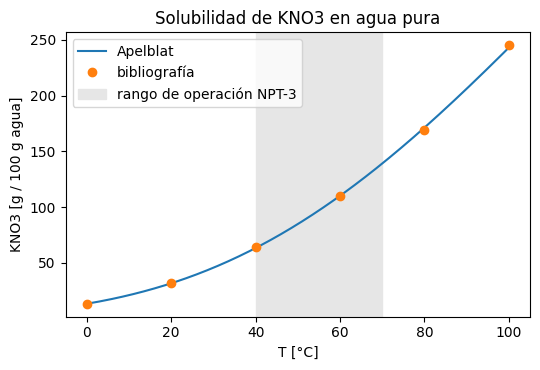

In [7]:
def apelblat(p, T_C):
    TK = np.asarray(T_C, dtype=float) + 273.15
    return np.exp(p[0] + p[1] / TK + p[2] * np.log(TK))

def ajustar_apelblat(T_C, m):
    res = least_squares(lambda p: np.log(apelblat(p, T_C)) - np.log(m), x0=[0.0, -1000.0, 0.0])
    return res.x, res.fun        # parámetros y residuos en ln(m)

P_APEL = {}
def registrar_curva(sal, tabla):
    P_APEL[sal], resid = ajustar_apelblat(tabla["T_C"].values, g100_a_molal(tabla["g_100g"], sal))
    print(f"{sal}: A={P_APEL[sal][0]:.3f}, B={P_APEL[sal][1]:.1f}, C={P_APEL[sal][2]:.4f} | "
          f"error relativo máx = {100*np.max(np.abs(np.expm1(resid))):.1f} %")

def m_sat_agua(sal, T_C):
    """Solubilidad en agua pura [mol/kg agua]."""
    return apelblat(P_APEL[sal], T_C)

def Ksp_ap(sal, T_C):
    """Producto de solubilidad aparente de una sal 1:1 en agua pura: K'sp = m_sat^2 [(mol/kg)^2]."""
    return m_sat_agua(sal, T_C) ** 2

def grafico_curva(sal, tabla):
    Tg = np.linspace(0, 100, 201)
    fig, a = plt.subplots(figsize=(5.5, 3.8))
    a.plot(Tg, m_sat_agua(sal, Tg) * M[sal] / 10, label="Apelblat")
    a.plot(tabla["T_C"], tabla["g_100g"], "o", label="bibliografía")
    a.axvspan(40, 70, color="0.9", label="rango de operación NPT-3")
    a.set(xlabel="T [°C]", ylabel=f"{sal} [g / 100 g agua]", title=f"Solubilidad de {sal} en agua pura")
    a.legend(); plt.tight_layout(); plt.show()

registrar_curva("KNO3", SOL_KNO3_AGUA)
grafico_curva("KNO3", SOL_KNO3_AGUA)

### 2.3 Extensión a la salmuera: ion común, factor de actividad y sobresaturación única

En el licor de SQM el K⁺ está compartido por el KNO₃ y el KClO₄, y el NO₃⁻ también aporta el NaNO₃ y el Mg(NO₃)₂. Para una sal 1:1 la condición de saturación es

$$m_{K^+}\, m_{X^-} = \Gamma_X \, K'_{sp,X}(T), \qquad X \in \{NO_3^-,\ ClO_4^-\}$$

- $K'_{sp,X}(T)$ es el producto aparente del sistema binario (sección 2.2).
- $\Gamma_X$ corrige la diferencia de coeficientes de actividad entre la salmuera y el binario saturado. Con $\Gamma = 1$ queda el **efecto de ion común ideal**.
- Para el efecto del Mg se usa una corrección empírica: $\ln\Gamma_X = \ln\Gamma_{X,0} + k_{X,Mg}\,(m_{Mg} - m_{Mg,ref})$.

**Consecuencias que salen del propio modelo (sin parámetros extra):**

- Como el licor tiene mucho K⁺ (KNO₃ casi saturado), la solubilidad del KClO₄ es **mucho menor que en agua pura**.
- Si baja el NaNO₃, baja el exceso de nitrato, la sal KNO₃ admite más K⁺ disuelto y, por ion común, **baja la solubilidad del KClO₄**. Es justo lo que reportó SQM.
- El Mg aporta nitrato (lo que por sí solo subiría la solubilidad del KClO₄), pero SQM observa lo contrario. Por eso el efecto del Mg **tiene que entrar por $k_{ClO_4,Mg} < 0$** y calibrarse con datos.

**Sobresaturación única.** Para una sal 1:1 se define

$$S_X = \sqrt{\frac{m_{K^+}\, m_{X^-}}{\Gamma_X\, K'_{sp,X}(T)}}, \qquad \sigma_X = S_X - 1$$

En agua pura se reduce a $\sigma = m/m_{sat} - 1 = \Delta C/C^*$, la misma definición del modelo anterior, así que es compatible con las cinéticas de bibliografía. **Todo el código usa `sobresaturacion()`**; ninguna otra función calcula σ por su cuenta.

In [8]:
# =========================================================
# 2.3 Funciones de equilibrio en la salmuera
# =========================================================
# Parámetros de actividad. Procedencia: 'calibrado' / 'supuesto' / 'pendiente'.
TERMO = {
    "lnGamma0": {"KNO3": 0.0, "KClO4": 0.0},          # KClO4 se calibra en 3.2; KNO3 pendiente (datos de MLK)
    "k_Mg":     {"KNO3": 0.0, "KClO4": 0.0},          # [kg/mol] pendiente: requiere ensayos a distinto Mg
    "m_Mg_ref": 2.0,                                  # [mol/kg] referencia del ajuste (≈ Mg del ensayo SQM)
}
PROCEDENCIA_TERMO = {"lnGamma0.KNO3": "pendiente (MLK)", "lnGamma0.KClO4": "calibrado en 3.2",
                     "k_Mg.KNO3": "pendiente", "k_Mg.KClO4": "pendiente (signo esperado < 0)"}

def Gamma(sal, m_Mg, termo=TERMO):
    return np.exp(termo["lnGamma0"][sal] + termo["k_Mg"][sal] * (m_Mg - termo["m_Mg_ref"]))

def sobresaturacion(sal, T_C, comp, termo=TERMO):
    """ÚNICA definición de sobresaturación del modelo.
    comp: dict con molalidades [mol/kg agua] de 'K', 'NO3', 'ClO4', 'Mg'.
    Devuelve sigma = S - 1, con S = sqrt(IAP / (Gamma * K'sp)). sigma < 0 significa subsaturado."""
    anion = {"KNO3": "NO3", "KClO4": "ClO4"}[sal]
    IAP = np.maximum(comp["K"] * comp[anion], 0.0)      # protege contra ruido numérico negativo
    return np.sqrt(IAP / (Gamma(sal, comp["Mg"], termo) * Ksp_ap(sal, T_C))) - 1.0

def m_K_eq_KNO3(T_C, comp, termo=TERMO):
    """K+ disuelto [mol/kg] cuando el licor está en equilibrio con KNO3 sólido.
    Al cristalizar x mol/kg de KNO3 se pierde lo mismo de K+ y de NO3-: el exceso d = NO3 - K se conserva."""
    d = comp["NO3"] - comp["K"]
    Kp = Gamma("KNO3", comp["Mg"], termo) * Ksp_ap("KNO3", T_C)
    return 0.5 * (-d + np.sqrt(d * d + 4.0 * Kp))

def m_ClO4_sat(T_C, m_K, m_Mg, termo=TERMO):
    """Solubilidad del perclorato [mol/kg] para un K+ dado (ion común)."""
    return Gamma("KClO4", m_Mg, termo) * Ksp_ap("KClO4", T_C) / m_K

### 2.4 Composición del licor de alimentación (SSK / SSKd)

Se usan las medianas de los análisis químicos de SQM (`AQ SSKd.xlsx`, octubre 2026, 356 muestras de SSK y 180 de SSKd). Se interpretan como **g/L de solución**, con NO₃ total informado también como "NaNO₃ equivalente" (681 × 62/85 ≈ 497, que coincide con la columna NO₃).

Para pasar de g/L a mol/kg de agua hace falta **cuánta agua hay en un litro de licor** ($w_{agua}$). Se toma del informe de parámetros de SQM para la corriente 334 SSK-d: fracción de agua 0,3994 kg/kg y densidad 1518 kg/m³, es decir, $w_{agua}$ = 0,606 kg/L. Es un dato de una sola corriente reconciliada, así que conviene verificarlo con la densidad y la humedad medidas del SSKd.

⚠ **Unidades por confirmar con SQM.** Además, los cationes medidos superan a los aniones medidos en ~4,4 eq/L. Lo más probable es que sea cloruro no analizado (NaCl/KCl arrastrado desde conversión), y eso también hay que confirmarlo.

In [9]:
# Medianas AQ SSKd.xlsx (oct-2026) [g/L]
LICOR_GL = {
    "SSK":  {"K": 251.0, "NO3": 503.0, "Mg": 28.8, "Na": 86.0, "ClO4": 4.4},
    "SSKd": {"K": 223.5, "NO3": 607.5 * M["NO3"] / M["NaNO3"], "Mg": 27.1, "ClO4": 4.1},
}
# Mg de SSKd = 27,1 g/L (muestra del ensayo de SQM); ClO4 de SSKd = 5,7 g/L KClO4 del ensayo -> 4,1 g/L ClO4.
W_AGUA_KG_L = 0.3994 * 1.518   # kg agua / L licor: informe de parámetros SQM, corriente 334 SSK-d (x_agua · ρ)

def gL_a_molal(comp_gL, w_agua=W_AGUA_KG_L):
    return {k: v / M[k] / w_agua for k, v in comp_gL.items()}

COMP = {n: gL_a_molal(c) for n, c in LICOR_GL.items()}
display(pd.DataFrame(COMP).round(3).rename_axis("mol/kg agua"))

# Balance de cargas del SSK (meq/L) para detectar iones no analizados
z = {"K": 1, "Na": 1, "Mg": 2, "NO3": -1, "ClO4": -1}
q = {k: z[k] * v / M[k] for k, v in LICOR_GL["SSK"].items()}
print(f"Desbalance de carga SSK = {sum(q.values()):.2f} eq/L (positivo = faltan aniones; ¿Cl-?)")

,SSK,SSKd
mol/kg agua,,
K,10.588,9.428
NO3,13.381,11.790
Mg,1.954,1.839
Na,6.170,NaN
ClO4,0.073,0.068


Desbalance de carga SSK = 4.37 eq/L (positivo = faltan aniones; ¿Cl-?)


### 2.5 Propiedades térmicas y estado de la sección

El calor de cristalización ($\Delta H_c = -7{,}73$ kcal/mol, dato SQM), el Cp del licor (2248 J/(kg·K), corriente 334 SSK-d) y la densidad del licor (1470 kg/m³, PFD GEA) están en `PROP` (sección 1). Por ahora son **constantes**: no dependen de T ni de la concentración. En el rango de operación (40–70 °C) el error esperado es menor que la incertidumbre de otros parámetros, pero queda como pendiente.

| Ítem de la checklist | Estado |
|---|---|
| Curva C*(T) del KNO₃ para el sistema complejo, ajustada con el MLK | 🟡 Ion común + Γ implementados; $\Gamma_{KNO_3}$ = 1 hasta tener KNO₃ medido en el MLK |
| Una única definición de sobresaturación | ✅ `sobresaturacion()` |
| Calor de cristalización del KNO₃ | ✅ en el balance de energía (sección 4) |
| Cp y densidad del licor función de T y concentración | 🟡 constantes con fuente |
| (Deseable) modelo de actividades Pitzer/OLI | ❌ pendiente |

## 3. Solubilidad del perclorato e interacción con el magnesio

Se aplica el mismo marco de la sección 2 (ion común + Γ) al KClO₄. En el licor de SQM, el K⁺ que comparte con el KNO₃ reduce mucho su solubilidad respecto del agua pura, y el NaNO₃ y el Mg la modifican.

,0,1,2,3,4,5
T_C,0.00,20.00,40.00,60.00,80.00,100.0
g_100g,0.76,1.73,3.63,7.18,13.38,22.2


KClO4: A=-11.130, B=-2481.9, C=3.0849 | error relativo máx = 2.4 %


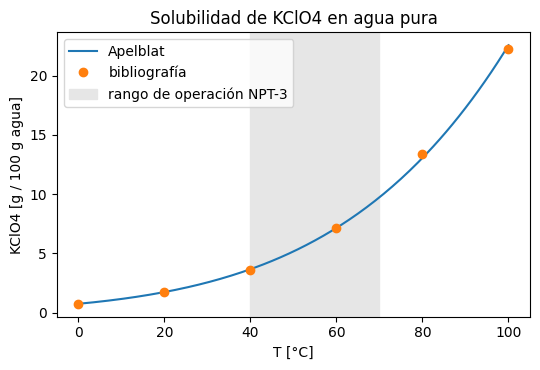

In [10]:
# =========================================================
# 3.1 Solubilidad del KClO4 en agua pura (bibliografía)
# =========================================================
# [g KClO4 / 100 g H2O]. Fuente: BOC Sciences, "Water solubility table at temperatures" (misma tabla que el KNO3;
# sin fuente citada en la página, valores coincidentes con el CRC Handbook). Reemplaza a la compilación anterior
# de varias fuentes (chemister.ru, J.T. Baker, Merck), cuyos puntos de 20, 25 y 40 °C eran inconsistentes.
SOL_KCLO4_AGUA = pd.DataFrame({
    "T_C":    [0,    20,   40,   60,   80,    100],
    "g_100g": [0.76, 1.73, 3.63, 7.18, 13.38, 22.2]})
display(SOL_KCLO4_AGUA.T)
registrar_curva("KClO4", SOL_KCLO4_AGUA)
grafico_curva("KClO4", SOL_KCLO4_AGUA)

### 3.2 Calibración de $\Gamma_{KClO_4}$ con el ensayo de SQM (validación de la curva)

El ensayo enfrió SSKd (≈ 27,1 g/L de Mg y 5,7 g/L de KClO₄) desde 74 °C y midió el KClO₄ disuelto. Bajo ~40 °C el licor está saturado en **ambas** sales, así que en cada punto:

1. el K⁺ disuelto es el que deja el KNO₃ en equilibrio (`m_K_eq_KNO3`);
2. el ClO₄⁻ disuelto es el de saturación para ese K⁺ (`m_ClO4_sat`).

Con los puntos de 25, 30 y 35 °C se ajusta **un solo parámetro**, $\ln\Gamma_{KClO_4,0}$. El punto de 40 °C es la inflexión y queda **fuera del ajuste**, porque ahí el licor apenas está llegando a saturación. Los puntos sobre 40 °C son licor subsaturado y sirven para verificar que el modelo prediga $\sigma < 0$.

Que un **único** $\Gamma$ constante reproduzca la pendiente con la temperatura es una prueba de que el mecanismo de ion común captura la física.

ln Γ_KClO4,0 = 1.571  (Γ = 4.81); error relativo máx. en 25–35 °C = 2.3 %


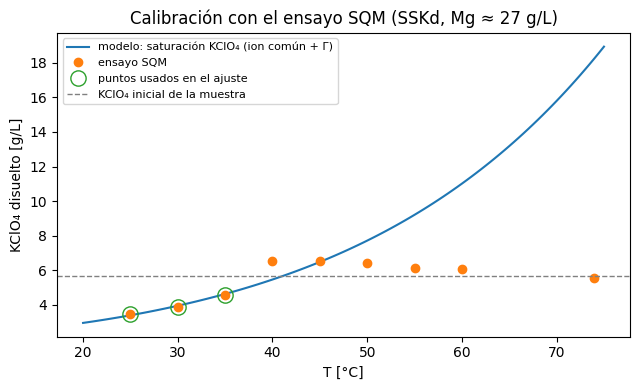

In [11]:
ENSAYO_SQM = pd.DataFrame({            # Informaciones Varias.docx, SQM
    "T_C":       [74,   60,   55,   50,   45,   40,   35,   30,   25],
    "KClO4_g_L": [5.57, 6.05, 6.12, 6.40, 6.54, 6.54, 4.59, 3.90, 3.48]})
saturado = ENSAYO_SQM["T_C"] <= 35

def predecir_ensayo(T_C, termo=TERMO, comp0=COMP["SSKd"], w_agua=W_AGUA_KG_L):
    """g/L de KClO4 disuelto predichos (licor saturado en KNO3 y KClO4)."""
    mK = m_K_eq_KNO3(T_C, comp0, termo)
    return m_ClO4_sat(T_C, mK, comp0["Mg"], termo) * M["KClO4"] * w_agua

def _res(p):
    t = copy.deepcopy(TERMO); t["lnGamma0"]["KClO4"] = p[0]
    d = ENSAYO_SQM[saturado]
    return np.log(predecir_ensayo(d["T_C"].values, t)) - np.log(d["KClO4_g_L"].values)

fit_G = least_squares(_res, x0=[1.0])
TERMO["lnGamma0"]["KClO4"] = float(fit_G.x[0])
TERMO["m_Mg_ref"] = COMP["SSKd"]["Mg"]
print(f"ln Γ_KClO4,0 = {fit_G.x[0]:.3f}  (Γ = {np.exp(fit_G.x[0]):.2f}); "
      f"error relativo máx. en 25–35 °C = {100*np.max(np.abs(np.expm1(fit_G.fun))):.1f} %")

Tp = np.linspace(20, 75, 111)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(Tp, predecir_ensayo(Tp), label="modelo: saturación KClO₄ (ion común + Γ)")
ax.plot(ENSAYO_SQM["T_C"], ENSAYO_SQM["KClO4_g_L"], "o", label="ensayo SQM")
ax.plot(ENSAYO_SQM["T_C"][saturado], ENSAYO_SQM["KClO4_g_L"][saturado], "o", mfc="none", ms=11, label="puntos usados en el ajuste")
ax.axhline(5.7, ls="--", c="0.5", lw=1, label="KClO₄ inicial de la muestra")
ax.set(xlabel="T [°C]", ylabel="KClO₄ disuelto [g/L]", title="Calibración con el ensayo SQM (SSKd, Mg ≈ 27 g/L)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 3.3 Holgura térmica y efectos del NaNO₃, del Mg y del agua de dilución

La **holgura térmica** es la diferencia entre la temperatura de operación y la temperatura a la que el KClO₄ empezaría a precipitar ($\sigma_{KClO_4} = 0$). Es el indicador más útil para SQM: cuántos grados le quedan al cristalizador antes de contaminar el producto con KClO₄ sólido.

Abajo se calcula para el licor en equilibrio con KNO₃ y con el ClO₄ concentrado por la evaporación. Para el **Mg** se muestran **escenarios** de $k_{ClO_4,Mg}$, porque con un solo ensayo (un solo nivel de Mg) ese parámetro **no es identificable**. Las curvas con $k \neq 0$ son ilustrativas y no son datos.

T de saturación predicha para la muestra del ensayo: 41.3 °C (ensayo: inflexión cerca de 40 °C; modelo SQM: 42,5 °C)


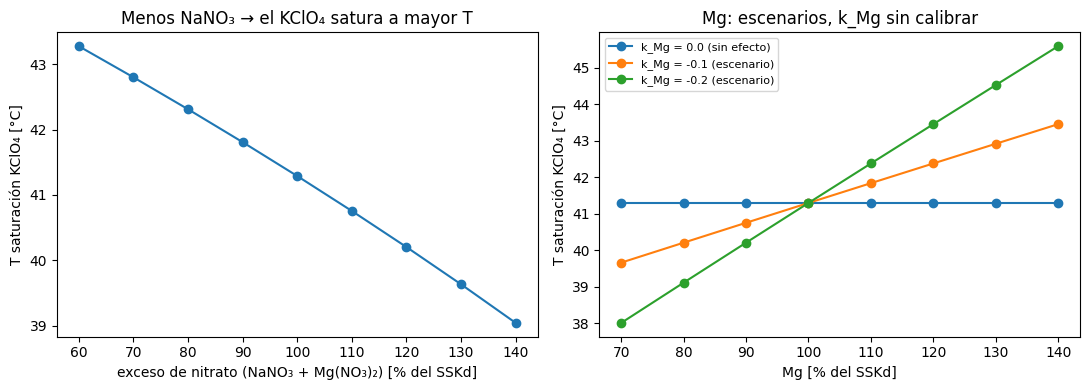

In [12]:
def T_saturacion_KClO4(comp, termo=TERMO, T_lo=5.0, T_hi=95.0):
    """T [°C] a la que sigma_KClO4 = 0 para un licor en equilibrio con KNO3 (comp: molalidades de entrada)."""
    def f(T):
        c = dict(comp); c["K"] = min(comp["K"], m_K_eq_KNO3(T, comp, termo))   # si el KNO3 está subsaturado, no cristaliza
        c["NO3"] = comp["NO3"] - (comp["K"] - c["K"])
        return sobresaturacion("KClO4", T, c, termo)
    if f(T_lo) < 0:  return np.nan     # no satura en el rango
    if f(T_hi) > 0:  return np.inf
    return brentq(f, T_lo, T_hi)

def holgura_termica(T_op, comp, termo=TERMO):
    return T_op - T_saturacion_KClO4(comp, termo)

# (a) Verificación con el ensayo: T a la que satura la muestra de SSKd
print(f"T de saturación predicha para la muestra del ensayo: {T_saturacion_KClO4(COMP['SSKd']):.1f} °C "
      "(ensayo: inflexión cerca de 40 °C; modelo SQM: 42,5 °C)")

# (b) Efecto del NaNO3 (sale del ion común, sin parámetros extra)
factores = np.linspace(0.6, 1.4, 9)
T_na = []
for f in factores:
    c = dict(COMP["SSKd"]); c["NO3"] = c["K"] + f * (COMP["SSKd"]["NO3"] - COMP["SSKd"]["K"])
    T_na.append(T_saturacion_KClO4(c))

# (c) Escenarios de Mg
mg_rel = np.linspace(0.7, 1.4, 8)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(100 * factores, T_na, "o-")
ax[0].set(xlabel="exceso de nitrato (NaNO₃ + Mg(NO₃)₂) [% del SSKd]", ylabel="T saturación KClO₄ [°C]",
          title="Menos NaNO₃ → el KClO₄ satura a mayor T")
for k in (0.0, -0.1, -0.2):
    t = copy.deepcopy(TERMO); t["k_Mg"]["KClO4"] = k
    Ts = [T_saturacion_KClO4({**COMP["SSKd"], "Mg": r * COMP["SSKd"]["Mg"]}, t) for r in mg_rel]
    ax[1].plot(100 * mg_rel, Ts, "o-", label=f"k_Mg = {k}" + (" (sin efecto)" if k == 0 else " (escenario)"))
ax[1].set(xlabel="Mg [% del SSKd]", ylabel="T saturación KClO₄ [°C]", title="Mg: escenarios, k_Mg sin calibrar")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Agua de dilución.** Diluir el SSKd baja todas las molalidades por igual. Como el producto $m_{K}\,m_{ClO_4}$ baja con el cuadrado del factor de dilución, el KClO₄ satura a menor temperatura y **aumenta la holgura**. Por eso SQM la considera una variable crítica de calidad. El cálculo de abajo es solo termodinámico (licor de alimentación); el efecto en el proceso completo, con evaporación y cristalización, está en las secciones 9 y 10.

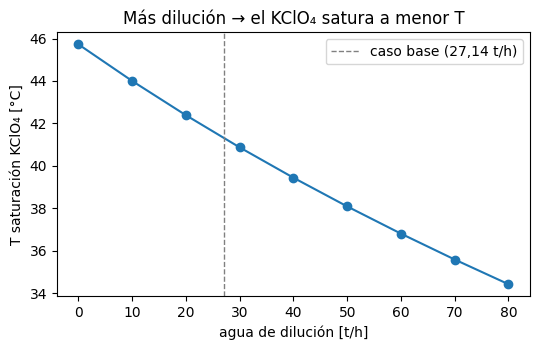

In [13]:
W_pre = (OPER["F_pre_kg_s"] + OPER["F_dil_kg_s"]) * PROP["x_agua_SSKd"] - OPER["F_dil_kg_s"]   # kg agua/s sin dilución
dil_t_h = np.linspace(0, 80, 9)
T_sat_dil = []
for d in dil_t_h:
    fac = (W_pre + OPER["F_dil_kg_s"]) / (W_pre + d / 3.6)        # molalidad relativa al SSKd base
    c = {k: v * fac for k, v in COMP["SSKd"].items()}
    T_sat_dil.append(T_saturacion_KClO4(c))
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(dil_t_h, T_sat_dil, "o-"); ax.axvline(27.14, ls="--", c="0.5", lw=1, label="caso base (27,14 t/h)")
ax.set(xlabel="agua de dilución [t/h]", ylabel="T saturación KClO₄ [°C]", title="Más dilución → el KClO₄ satura a menor T")
ax.legend(); plt.tight_layout(); plt.show()

### 3.4 Estado de la sección

| Elemento | Estado | Procedencia |
|---|---|---|
| Curva KNO₃–agua (Apelblat) | ✅ | tabla BOC Sciences (coincide con CRC); citar el CRC en el informe |
| Curva KClO₄–agua (Apelblat) con ion común K⁺ | ✅ | misma tabla, 0–100 °C (reemplaza la compilación dispersa anterior) |
| Validación con el ensayo de SQM | ✅ | inflexión predicha a ~41,3 °C (ensayo: ~40 °C; modelo SQM: 42,5 °C) |
| Efecto NaNO₃ | ✅ | sale del ion común; coincide en signo con SQM |
| Efecto Mg sobre KClO₄ y KNO₃ | 🟡 | estructura lista ($k_{Mg}$); requiere un ensayo a otro nivel de Mg |
| Agua de dilución como variable de calidad | ✅ | termodinámica aquí; proceso completo en secciones 9 y 10 |
| $\Gamma_{KNO_3,0}$ | ❌ | requiere KNO₃ en el MLK a T conocida |
| Unidades de AQ SSKd y Cl⁻ no analizado | ❌ | confirmar con SQM |

**Datos para pedir a SQM:** densidad y contenido de agua del SSKd y del MLK; análisis completo del MLK de A3110 y A3210 con la temperatura de cada equipo; un segundo ensayo de enfriamiento con SSKd a otro nivel de Mg.

## 4. Modo evaporativo (flash al vacío)

Cada cristalizador (A3110 y A3210) opera al vacío. La presión fija la temperatura de ebullición del licor y el agua se evapora hasta que el licor llega a esa temperatura. El modelo supone que el lazo de vacío mantiene **T constante**, así que la evaporación no es un dato: **se despeja del balance de energía** de cada etapa.

$$\dot m_{evap}\,\lambda(T) = \dot m_{liq,in}\, c_{p,l}(T_{in} - T) + \dot m_{c,in}\, c_{p,c}(T_{in} - T) + \Delta H_c\, \dot R_{KNO_3} M_{KNO_3}$$

- El primer y el segundo término son el calor sensible del licor y de los cristales que entran más calientes. El tercero es el calor liberado al cristalizar (−7,73 kcal/mol).
- La relación entre presión y temperatura es $T = T_{sat,agua}(P) + BPE$, con Antoine para el agua pura y la elevación del punto de ebullición (BPE) por las sales.
- **Dos etapas en serie** (70 → 55 → 40 °C): la pulpa de A3110 (licor + cristales) alimenta a A3210, así que la segunda etapa recibe **cristales sembrados**.
- **Alimentación con cristales (semillas):** `OPER["siembra_alim"]` permite que el SSKd traiga cristales con la CSD de planta de A3110. El caso base usa 0 (licor claro), porque no está confirmado que el SSKd traiga sólidos.
- **Agua de dilución:** entra con la alimentación de A3110. Los flujos de iones y de inertes son los del SSK + licor; la dilución solo agrega agua.

In [14]:
# =========================================================
# 4.1 Vacío, alimentación (con dilución y semillas) e inventarios
# =========================================================
for k in (1, 2):
    print(f"Etapa {k}: T = {OPER['T_C'][k]} °C, P = {OPER['P_kPa'][k]} kPa, "
          f"BPE implícito = {OPER['T_C'][k] - tsat_agua(OPER['P_kPa'][k]):.2f} °C")

# Composición del SSKd base (sección 2) en base de agua; lo no analizado se agrupa como "inertes"
FEED = dict(COMP["SSKd"])                                                       # mol / kg agua
masa_ionica = sum(FEED[s] * M[s] / 1000 for s in ("K", "NO3", "Mg", "ClO4"))   # kg / kg agua
FEED["inertes_kg"] = 1 / PROP["x_agua_SSKd"] - 1 - masa_ionica                  # kg / kg agua

# Flujos del caso base: los iones y los inertes vienen con el SSK + licor; la dilución solo aporta agua
W_SSKd_BASE = (OPER_BASE["F_pre_kg_s"] + OPER_BASE["F_dil_kg_s"]) * PROP["x_agua_SSKd"]
W_PRE_BASE = W_SSKd_BASE - OPER_BASE["F_dil_kg_s"]

def w_clase_planta(k=1):
    """Fracción másica por clase de la CSD promedio de planta (para semillas y arranque)."""
    pas = np.interp(np.log(EDGES[1:]), np.log(MALLAS_UM * 1e-6), AG_PLANTA[k]["media"], left=0, right=100)
    return np.diff(np.concatenate([[0.0], pas])) / 100

def entrada_SSKd(oper=OPER, feed=FEED, f=None):
    """Flujos que entran a A3110 [unidades/s]: SSK + licor (escalado con F_pre), agua de dilución y semillas."""
    f = FORMA if f is None else f
    esc = oper["F_pre_kg_s"] / OPER_BASE["F_pre_kg_s"]
    e = {s: feed[s] * W_SSKd_BASE * esc for s in ("K", "NO3", "ClO4", "Mg")}
    W = W_PRE_BASE * esc + oper["F_dil_kg_s"]
    m_sem = oper.get("siembra_alim", 0.0) * (oper["F_pre_kg_s"] + oper["F_dil_kg_s"])
    N_in = m_sem * w_clase_planta(1) / (PROP["rho_c"] * f["kv"] * L3)
    e.update(W=W, I=feed["inertes_kg"] * W_SSKd_BASE * esc, P=0.0, N=N_in, z=np.zeros(NCLASES), T_in=oper["T_feed_C"])
    return e

def inventarios(oper=OPER):
    """Masa total de cada etapa [kg] = tau * flujo NOMINAL de entrada (lazo de nivel).
    Si cambia la alimentación, el nivel (inventario) se mantiene y el tiempo de residencia efectivo cambia;
    si cambia tau, cambia la consigna de nivel."""
    F = OPER_BASE["F_pre_kg_s"] + OPER_BASE["F_dil_kg_s"]
    return {1: oper["tau_h"][1] * 3600 * F, 2: oper["tau_h"][2] * 3600 * F}

e0 = entrada_SSKd()
print(f"Agua alimentada = {3.6*e0['W']:.1f} t/h (de ella, {3.6*OPER['F_dil_kg_s']:.2f} t/h de dilución); "
      f"inertes = {FEED['inertes_kg']:.3f} kg/kg agua")
for T in (70, 55, 40):
    print(f"  sigma_KNO3 del SSKd a {T} °C (sin evaporar ni cristalizar) = {sobresaturacion('KNO3', T, FEED):+.3f}")

Etapa 1: T = 55.0 °C, P = 11.59 kPa, BPE implícito = 6.20 °C
Etapa 2: T = 40.0 °C, P = 5.43 kPa, BPE implícito = 5.59 °C
Agua alimentada = 161.9 t/h (de ella, 27.14 t/h de dilución); inertes = 0.353 kg/kg agua
  sigma_KNO3 del SSKd a 70 °C (sin evaporar ni cristalizar) = -0.234
  sigma_KNO3 del SSKd a 55 °C (sin evaporar ni cristalizar) = +0.099
  sigma_KNO3 del SSKd a 40 °C (sin evaporar ni cristalizar) = +0.684


### 4.2 Estado de la sección

| Ítem de la checklist | Estado |
|---|---|
| Evaporativo con agua evaporada por balance de energía | ✅ (se calcula en cada etapa; resultados en la sección 6) |
| Presión de vacío ↔ T con Antoine + BPE | 🟡 BPE implícito constante por etapa; no depende de la composición |
| Concentración de impurezas por evaporación conectada con la saturación del KClO₄ | ✅ la molalidad del ClO₄ sube con la evaporación y entra en `sobresaturacion("KClO4")` |
| Dos etapas en serie en el modelo dinámico | ✅ |
| Alimentación con semillas (PBE de cristales en la entrada) | ✅ `OPER["siembra_alim"]` (caso base: 0) |
| (Deseable) condensadores y agua de enfriamiento | ❌ pendiente |
| (Deseable) zona de ebullición con σ local mayor | ❌ declarada como supuesto (mezcla perfecta) |

## 5. Balances

**Estados de cada etapa**

- $W$: kg de agua; $n_K, n_{NO_3}, n_{ClO_4}, n_{Mg}$: mol disueltos; $I$: kg de inertes (Na⁺, Cl⁻, SO₄²⁻ y otros no analizados en el SSKd).
- $N_i$: número de cristales de KNO₃ en la clase de tamaño $i$; $z_i$: kg de ClO₄ incorporado en esos cristales.
- $P$: kg de KClO₄ sólido coprecipitado.

**Balances de materia** (para cada especie disuelta $s$):

$$\frac{dn_s}{dt} = \dot n_{s,in} - r_{out}\, n_s - \nu_s\, \dot R_{KNO_3} - \nu'_s\, \dot R_{KClO_4} - \dot R_{inc}\,\delta_{s,ClO_4}, \qquad \frac{dW}{dt} = \dot W_{in} - r_{out}W - \dot m_{evap}$$

- $\dot R_{KNO_3}$ sale de la PBE (masa de cristal que aparece por crecimiento y nucleación, sección 6).
- $\dot R_{KClO_4}$ es la coprecipitación de KClO₄, y $\dot R_{inc}$ el perclorato que queda atrapado en el KNO₃ que crece (sección 8).

**Nivel constante y volumen de los cristales.** La masa total de cada etapa ($M_k = \tau_k\,\dot m_{in}$) no cambia, así que $r_{out}$ se despeja de $\dot m_{out} = \dot m_{in} - \dot m_{evap}$. Como el inventario es **en masa e incluye los cristales**, el tiempo de residencia ya considera el espacio que ocupan los sólidos. El volumen de pulpa que resulta se compara con los 660 m³ en la sección 9.

**Arranque.** Cada etapa parte llena de licor de alimentación con una carga de siembra (10 % en masa, con la CSD de planta); el licor inicial de A3210 parte en equilibrio con el KNO₃ a 40 °C y, durante el arranque, la nucleación de KClO₄ se desactiva: el transitorio artificial del arranque podría sembrar KClO₄ que la planta, que llegó a su estado de operación gradualmente, no tiene. Una vez en el estacionario, todos los análisis usan la cinética completa del KClO₄. Con nucleación secundaria ($B_s \propto M_T$), un tanque sin cristales podría quedarse sin cristales; la siembra solo elige el estado estacionario con cristales, que es el de planta. El resultado estacionario no depende de esa carga.

In [15]:
# =========================================================
# 5.1 Ecuaciones de una etapa y del tren de dos etapas
# =========================================================
def _desempacar(x):
    W, nK, nN, nP, nMg, I, P = x[:NESP]
    N = x[NESP:NESP + NCLASES]; z = x[NESP + NCLASES:]
    return W, nK, nN, nP, nMg, I, P, N, z

def tasas(x, T, kin=KIN, imp=IMP, f=None):
    """Variables algebraicas de una etapa: sobresaturaciones, G, B, masas, etc."""
    f = FORMA if f is None else f
    W, nK, nN, nP, nMg, I, P, N, z = _desempacar(x)
    W = max(W, 1e-9)
    comp = {"K": nK / W, "NO3": nN / W, "ClO4": nP / W, "Mg": nMg / W}
    sig = sobresaturacion("KNO3", T, comp)
    sigP = sobresaturacion("KClO4", T, comp)
    m_c = PROP["rho_c"] * f["kv"] * np.dot(N, L3)                       # kg KNO3 sólido
    m_liq = W + I + sum(comp[s] * W * M[s] / 1000 for s in ("K", "NO3", "ClO4", "Mg"))
    V = m_liq / PROP["rho_liq"] + (m_c + P) / PROP["rho_c"]             # m3 de pulpa
    MT = m_c / V
    arr = np.exp(-kin["Eg"] / R_GAS * (1 / (T + 273.15) - 1 / (kin["Tref"] + 273.15)))
    if sig >= 0:
        G = kin["kg"] * arr * sig ** kin["g"] * (1 + kin["gamma"] * EDGES[1:])   # en las caras superiores
        B = (kin["kbp"] * sig ** kin["bp"] + kin["kbs"] * sig ** kin["bs"] * MT ** kin["j"]) * V
    else:
        G = kin["kdis"] * sig * np.ones(NCLASES); B = 0.0
    return dict(comp=comp, sigma=sig, sigma_KClO4=sigP, G=G, B=B, m_c=m_c, m_liq=m_liq, V=V, MT=MT,
                x_ClO4=comp["ClO4"] * W * M["ClO4"] / 1000 / m_liq)

def rhs_etapa(x, T, entrada, M_tot, kin=KIN, imp=IMP, f=None):
    """Derivadas de una etapa. entrada: dict de flujos [unidades/s] y T_in.
    Devuelve (dx, salida) donde salida son los flujos que deja la etapa."""
    f = FORMA if f is None else f
    W, nK, nN, nP, nMg, I, P, N, z = _desempacar(x)
    a = tasas(x, T, kin, imp, f)
    G = a["G"]
    # --- PBE: flujos en las caras (upwind)
    dens = N / DL
    Fc = np.zeros(NCLASES + 1)                       # Fc[i+1] = flujo de la clase i a la i+1
    if a["sigma"] >= 0:
        Fc[1:-1] = G[:-1] * dens[:-1]
        Fc[-1] = 0.0                                 # sin salida por el borde superior
    else:
        Fc[1:] = G * np.append(dens[1:], 0.0)        # G<0: de i+1 hacia i
        Fc[0] = G[0] * dens[0]                       # disolución completa de la clase 0
    dN_crec = Fc[:-1] - Fc[1:]
    dN_crec[0] += a["B"]
    # razón ClO4/cristal transportada con el flujo
    ratio = np.divide(z, N, out=np.zeros_like(z), where=N > 1e-30)
    if a["sigma"] >= 0:
        Fz = np.concatenate([[0.0], Fc[1:-1] * ratio[:-1], [0.0]])
    else:
        Fz = np.concatenate([Fc[:1] * ratio[:1], Fc[1:-1] * ratio[1:], [0.0]])
    dz_crec = Fz[:-1] - Fz[1:]
    # masa formada por crecimiento + nucleación (consistente con m_c)
    mdot_crec = PROP["rho_c"] * f["kv"] * np.dot(dN_crec, L3)          # kg/s (negativo si disuelve)
    R_KNO3 = mdot_crec / (M["KNO3"] / 1000)                            # mol/s
    # --- Perclorato incorporado
    Gm = np.average(G, weights=np.maximum(N * L2, 1e-300)) if a["sigma"] > 0 else 0.0
    keff = imp["k0"] / (imp["k0"] + (1 - imp["k0"]) * np.exp(-Gm * imp["delta_D"])) \
           + imp["kinc"] * (Gm / imp["Gref"]) ** imp["n"]
    R_inc = keff * a["x_ClO4"] * max(mdot_crec, 0.0)                   # kg ClO4/s
    w_sup = np.maximum(N * L2 * np.maximum(G, 0), 0.0)
    dz_inc = R_inc * w_sup / w_sup.sum() if w_sup.sum() > 0 else np.zeros(NCLASES)
    ClO4_disuelto = -Fz[0] if a["sigma"] < 0 else 0.0                  # kg/s: ClO4 de cristales que se disuelven por completo
    # --- Coprecipitación KClO4 (cinética rápida)
    sP = a["sigma_KClO4"]; sZM = np.inf if imp["sigmaZM_KClO4"] is None else imp["sigmaZM_KClO4"]
    Pp = max(P, 0.0)
    if sP >= 0:
        # nucleación solo sobre la zona metaestable (rampa continua de ancho 0,002, cero bajo sZM);
        # si ya hay sólido, crece mientras sP > 0
        # (se exige más de 1 kg de sólido para el crecimiento, así el ruido numérico no "siembra" KClO4)
        act = max(min(max((sP - sZM) / 2e-3, 0.0), 1.0), max(Pp - 1.0, 0.0) / (Pp + 10.0))
        R_P = imp["kp_KClO4"] * W * sP * act    # mol/s
    else:                                       # se redisuelve si hay sólido
        R_P = imp["kp_KClO4"] * W * sP * Pp / (Pp + 1.0)
    # --- Energía: evaporación
    T_in = entrada["T_in"]
    mliq_in = entrada["W"] + entrada["I"] + sum(entrada[s] * M[s] / 1000 for s in ("K", "NO3", "ClO4", "Mg"))
    mc_in = PROP["rho_c"] * f["kv"] * np.dot(entrada["N"], L3) + entrada["P"]
    m_evap = (mliq_in * PROP["cp_liq"] * (T_in - T) + mc_in * PROP["cp_c"] * (T_in - T)
              + PROP["dHc_J_kg"] * mdot_crec) / lambda_agua(T)
    # --- Nivel constante: r_out
    m_out = mliq_in + mc_in - m_evap
    m_c_clas = PROP["rho_c"] * f["kv"] * np.dot(H_CLAS * N, L3)
    r_out = m_out / (a["m_liq"] + m_c_clas + P)
    # --- Derivadas
    dW = entrada["W"] - r_out * W - m_evap
    dK = entrada["K"] - r_out * nK - R_KNO3 - R_P
    dN3 = entrada["NO3"] - r_out * nN - R_KNO3
    dCl = entrada["ClO4"] - r_out * nP - R_P + (ClO4_disuelto - R_inc) / (M["ClO4"] / 1000)
    dMg = entrada["Mg"] - r_out * nMg
    dI = entrada["I"] - r_out * I
    dPs = entrada["P"] - r_out * P + R_P * M["KClO4"] / 1000
    dNi = entrada["N"] + dN_crec - r_out * H_CLAS * N
    dzi = entrada["z"] + dz_crec + dz_inc - r_out * H_CLAS * z
    dx = np.concatenate([[dW, dK, dN3, dCl, dMg, dI, dPs], dNi, dzi])
    salida = {"W": r_out * W, "K": r_out * nK, "NO3": r_out * nN, "ClO4": r_out * nP, "Mg": r_out * nMg,
              "I": r_out * I, "P": r_out * P, "N": r_out * H_CLAS * N, "z": r_out * H_CLAS * z, "T_in": T}
    diag = dict(a, m_evap=m_evap, mdot_crec=mdot_crec, R_inc=R_inc, R_P=R_P, keff=keff, r_out=r_out, m_out=m_out)
    return dx, salida, diag

def rhs_tren(t, y, oper=OPER, kin=KIN, imp=IMP, f=None):
    x1, x2 = y[:NEST], y[NEST:]
    Mt = inventarios(oper)
    dx1, sal1, _ = rhs_etapa(x1, oper["T_C"][1], entrada_SSKd(oper, f=f), Mt[1], kin, imp, f)
    dx2, _, _ = rhs_etapa(x2, oper["T_C"][2], sal1, Mt[2], kin, imp, f)
    return np.concatenate([dx1, dx2])

def estado_inicial(oper=OPER, siembra=0.10, f=None):
    """Arranque: cada etapa llena de licor de alimentación más una carga de siembra (fracción másica `siembra`)
    con la CSD promedio de planta. La siembra solo elige el estado estacionario con cristales: con nucleación
    secundaria (B ∝ M_T) un tanque sin cristales podría quedarse sin cristales."""
    f = FORMA if f is None else f
    e = entrada_SSKd(oper, f=f); Mt = inventarios(oper)
    masa_por_kg_agua = 1 / PROP["x_agua_SSKd"]
    w_clase = w_clase_planta(1)
    y = []
    for k in (1, 2):
        m_siembra = siembra * Mt[k]
        N0 = m_siembra * w_clase / (PROP["rho_c"] * f["kv"] * L3)
        W = (Mt[k] - m_siembra) / masa_por_kg_agua; fac = W / e["W"]
        nK, nN = e["K"] * fac, e["NO3"] * fac
        if k == 2:   # licor inicial de A3210 en equilibrio con KNO3 a su T: evita una sobresaturación artificial de KClO4
            c0 = {"K": nK / W, "NO3": nN / W, "Mg": e["Mg"] * fac / W, "ClO4": e["ClO4"] * fac / W}
            dK = max(0.0, c0["K"] - m_K_eq_KNO3(oper["T_C"][2], c0)) * W
            nK, nN = nK - dK, nN - dK
        y.append(np.concatenate([[W, nK, nN, e["ClO4"]*fac, e["Mg"]*fac, e["I"]*fac, 0.0],
                                 N0, np.zeros(NCLASES)]))
    return np.concatenate(y)

In [16]:
# =========================================================
# 5.2 Integración y resultados por etapa
# =========================================================
def simular(t_h=25.0, oper=OPER, kin=KIN, imp=IMP, f=None, y0=None, n_out=200):
    """Integra el tren. Sin y0 parte del arranque (estado_inicial); en ese caso la nucleación de KClO4 se
    desactiva, porque el transitorio artificial del arranque podría sembrar KClO4 que en planta no existe."""
    if y0 is None:
        y0 = ajustar_inventario(estado_inicial(oper, f=f), oper, f)
        imp = dict(imp, sigmaZM_KClO4=np.inf)
    else:
        y0 = ajustar_inventario(y0, oper, f)     # aplica la consigna de nivel si cambió tau
    opciones = dict(t_eval=np.linspace(0, t_h * 3600, n_out), rtol=1e-6, atol=1e-9 * np.maximum(np.abs(y0), 1.0))
    for extra in ({"method": "BDF", "jac_sparsity": JAC_SP},                      # intento normal
                  {"method": "BDF", "jac_sparsity": JAC_SP, "first_step": 1.0},   # reintento con paso inicial fijo
                  {"method": "LSODA"}):                                          # último recurso
        try:
            sol = solve_ivp(rhs_tren, (0, t_h * 3600), y0, args=(oper, kin, imp, f), **opciones, **extra)
            if sol.success:
                return sol
        except (RuntimeError, np.linalg.LinAlgError):
            pass
    raise RuntimeError("la integración no convergió con ningún método")

def masa_etapa(x, f=None):
    f = FORMA if f is None else f
    W, nK, nN, nP, nMg, I, P, N, z = _desempacar(x)
    m_liq = W + I + (nK * M["K"] + nN * M["NO3"] + nP * M["ClO4"] + nMg * M["Mg"]) / 1000
    return m_liq + PROP["rho_c"] * f["kv"] * N @ L3 + P

def ajustar_inventario(y, oper=OPER, f=None):
    """Escala los estados extensivos de cada etapa para que su masa sea la del inventario de `oper`
    (conserva la composición y la forma de la CSD)."""
    y = y.copy(); Mt = inventarios(oper)
    for k in (1, 2):
        s = slice((k - 1) * NEST, k * NEST)
        fac = Mt[k] / masa_etapa(y[s], f)
        if abs(fac - 1) > 1e-9:
            y[s] *= fac
    return y

def resultados_etapa(x, k, entrada, oper=OPER, kin=KIN, imp=IMP, f=None):
    f = FORMA if f is None else f
    Mt = inventarios(oper)
    dx, sal, d = rhs_etapa(x, oper["T_C"][k], entrada, Mt[k], kin, imp, f)
    W, nK, nN, nP, nMg, I, P, N, z = _desempacar(x)
    masa_i = PROP["rho_c"] * f["kv"] * N * L3
    pas = 100 * np.cumsum(masa_i) / masa_i.sum() if masa_i.sum() > 0 else np.zeros(NCLASES)
    pas_mallas = np.interp(MALLAS_UM * 1e-6, EDGES[1:], pas)
    sol_pct = 100 * (d["m_c"] + P) / (d["m_liq"] + d["m_c"] + P)
    w_L = W / (d["m_liq"] / PROP["rho_liq"]) / 1000                     # kg agua / L licor
    return dict(diag=d, salida=sal, pasante_mallas=pas_mallas, pasante=pas,
                D50_um=d_pct(MALLAS_UM, pas_mallas, 50) if masa_i.sum() > 0 else np.nan,
                finos100_pct=float(np.interp(100e-6, EDGES[1:], pas)),
                solidos_pct=sol_pct, prod_t_h=3.6 * sal["N"] @ L3 * PROP["rho_c"] * f["kv"],
                evap_t_h=3.6 * d["m_evap"], ppm_inc=1e6 * z.sum() / max(d["m_c"], 1e-12),
                ppm_coprec=1e6 * max(P, 0.0) / max(d["m_c"], 1e-12),
                ppm_clase=1e6 * np.divide(z, masa_i, out=np.zeros_like(z), where=masa_i > 0),
                licor_g_L={s: d["comp"][s] * M[s] * w_L for s in ("K", "NO3", "ClO4", "Mg")})

def resultados_tren(y, oper=OPER, kin=KIN, imp=IMP, f=None):
    e1 = entrada_SSKd(oper, f=f)
    r1 = resultados_etapa(y[:NEST], 1, e1, oper, kin, imp, f)
    r2 = resultados_etapa(y[NEST:], 2, r1["salida"], oper, kin, imp, f)
    return r1, r2

### 5.3 Verificación de los balances

Se integra el arranque hasta el estado estacionario y se compara, para el tren completo, lo que entra con lo que sale:

- **K⁺ y NO₃⁻:** lo que entra (disuelto + semillas) = lo disuelto que sale + lo cristalizado (KNO₃ y KClO₄).
- **Agua:** lo que entra = lo que sale en la pulpa + lo evaporado en las dos etapas.
- **ClO₄⁻:** lo que entra = lo disuelto + lo incorporado al cristal + lo coprecipitado.

In [17]:
def cierre_balances(y, oper=OPER, kin=KIN, imp=IMP, f=None):
    f = FORMA if f is None else f
    e = entrada_SSKd(oper, f=f)
    r1, r2 = resultados_tren(y, oper, kin, imp, f)
    s = r2["salida"]
    nKNO3_out = PROP["rho_c"] * f["kv"] * s["N"] @ L3 / (M["KNO3"] / 1000)
    nKNO3_in = PROP["rho_c"] * f["kv"] * e["N"] @ L3 / (M["KNO3"] / 1000)
    nKClO4 = s["P"] / (M["KClO4"] / 1000)
    evap = r1["diag"]["m_evap"] + r2["diag"]["m_evap"]
    err = {
        "K":    (s["K"] + nKNO3_out + nKClO4 - e["K"] - nKNO3_in) / (e["K"] + nKNO3_in),
        "NO3":  (s["NO3"] + nKNO3_out - e["NO3"] - nKNO3_in) / (e["NO3"] + nKNO3_in),
        "H2O":  (s["W"] + evap - e["W"]) / e["W"],
        "ClO4": (s["ClO4"] + s["z"].sum() / (M["ClO4"] / 1000) + nKClO4 - e["ClO4"]) / e["ClO4"],
    }
    return {k: float(v) for k, v in err.items()}

def deriva_maxima(y, oper=OPER, kin=KIN, imp=IMP, f=None):
    d = np.abs(rhs_tren(0, y, oper, kin, imp, f)) / np.maximum(np.abs(y), 1e-12)
    return float(np.nanmax(d[np.abs(y) > 1e-6 * np.abs(y).max()]))

t0 = time.time()
sol0 = simular(t_h=25.0)
y_ss0 = sol0.y[:, -1]
print(f"Integración: {time.time()-t0:.1f} s, {sol0.t.size} puntos")
print("Error relativo de cierre (debe ser ~0 en estado estacionario):",
      {k: f"{v:.1e}" for k, v in cierre_balances(y_ss0).items()})
print(f"Máxima derivada relativa al final: {deriva_maxima(y_ss0):.1e} 1/s")

Integración: 7.1 s, 200 puntos
Error relativo de cierre (debe ser ~0 en estado estacionario): {'K': '2.0e-05', 'NO3': '2.0e-05', 'H2O': '1.8e-05', 'ClO4': '2.0e-05'}
Máxima derivada relativa al final: 1.6e-06 1/s


### 5.4 Estado de la sección

| Ítem de la checklist | Estado |
|---|---|
| Balances por componente H₂O, KNO₃, ClO₄, Mg, Na y Cl | 🟡 H₂O, K, NO₃, ClO₄ y Mg por separado; Na⁺ y Cl⁻ agrupados como inertes (no hay Na ni Cl medidos en el SSKd) |
| Consistencia dinámico ↔ estacionario | ✅ el estacionario es el final de la integración (derivada relativa ~10⁻⁶ 1/s) |
| Etapa 2 alimentada con la pulpa de la etapa 1 | ✅ |
| Cierre de masa | ✅ error ~10⁻⁵ en K, NO₃, H₂O y ClO₄ |
| Volumen ocupado por los cristales | ✅ inventario en masa con sólidos; volumen de pulpa calculado (sección 9) |

## 6. Cinética y balance de población

**Balance de población** (volúmenes finitos, esquema upwind):

$$\frac{dN_i}{dt} = \dot N_{i,in} + \big(F_{i-1/2} - F_{i+1/2}\big) + B\,\delta_{i,0} - r_{out}\, h_i\, N_i, \qquad F = G(L)\,\frac{N}{\Delta L}$$

$h_i$ es la función de clasificación de la descarga. Vale 1 en un MSMPR. El DTB podría tener clasificación (retiro de finos), pero no está confirmado; la función queda disponible más abajo.

**Leyes cinéticas**

- **Crecimiento** dependiente del tamaño (forma ASL simplificada) con Arrhenius: $G = k_g\, e^{-E_g/R\,(1/T - 1/T_{ref})}\, \sigma^{g}\, (1 + \gamma L)$.
- **Nucleación primaria** $B_p = k_{bp}\,\sigma^{b_p}$ y **secundaria** $B_s = k_{bs}\,\sigma^{b_s}\, M_T^{j}$ ($M_T$ en kg de cristal por m³ de pulpa). En cristalizadores industriales con mucha masa de sólidos domina la secundaria.
- **Disolución** ($\sigma < 0$): $G = k_{dis}\,\sigma$.

Los exponentes se fijan en valores típicos de bibliografía ($g = 1$, $b_s = 2$, $j = 1$, $b_p = 5$). La granulometría de planta solo identifica $\theta = \log_{10}(k_{bs}/k_g^2)$ y $\gamma$ (sección 10).

### 6.1 Caso base: arranque y CSD frente a planta

Cierre de balances: {'K': '2.0e-05', 'NO3': '2.0e-05', 'H2O': '1.8e-05', 'ClO4': '2.0e-05'}


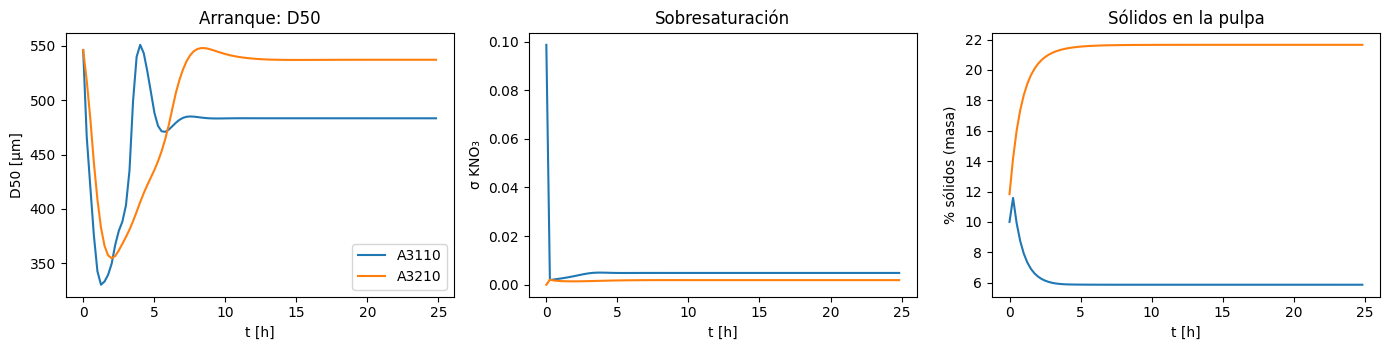

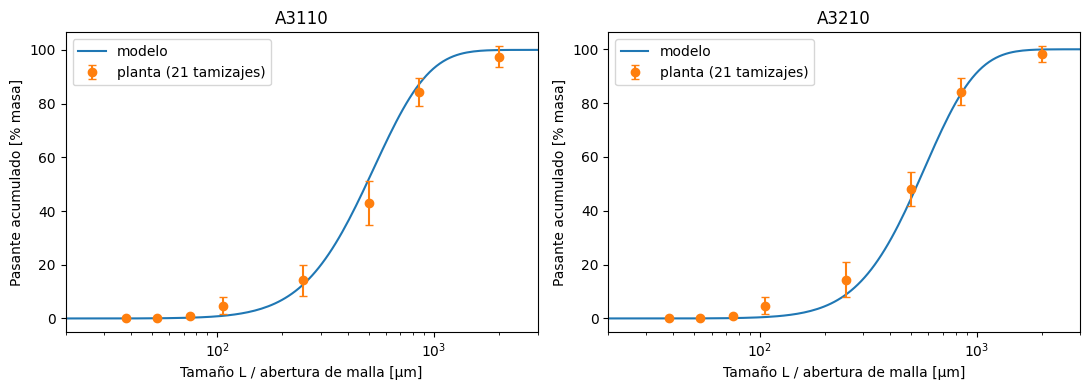

,A3110,A3210
T [°C],55.0,40.0
σ KNO₃,0.0049,0.0019
G medio [m/s],4.85e-08,1.89e-08
D50 modelo / planta [µm],483 / 547,537 / 515
finos < 100 µm modelo / planta [%],0.8 / 4.0,0.4 / 3.9
% sólidos (masa),5.9,21.7
evaporación [t/h],8.90,13.31
KNO₃ sólido que sale [t/h],23.2,83.0


Referencias: evaporación A3110 ≈ 10,03 t/h (balance v6); sólidos ≈ 13 % (A3110) y 20 % (A3210) (Entrega 2).


In [18]:
sol = simular(t_h=25.0, n_out=300)
y_ss = sol.y[:, -1]
r1, r2 = resultados_tren(y_ss)
print("Cierre de balances:", {k: f"{v:.1e}" for k, v in cierre_balances(y_ss).items()})

th = sol.t / 3600
traj = {k: [] for k in ("D50_1", "D50_2", "sig1", "sig2", "sol1", "sol2")}
for i in range(0, sol.t.size, 3):
    a1, a2 = resultados_tren(sol.y[:, i])
    traj["D50_1"].append(a1["D50_um"]); traj["D50_2"].append(a2["D50_um"])
    traj["sig1"].append(a1["diag"]["sigma"]); traj["sig2"].append(a2["diag"]["sigma"])
    traj["sol1"].append(a1["solidos_pct"]); traj["sol2"].append(a2["solidos_pct"])
tt = th[::3]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(tt, traj["D50_1"], label="A3110"); ax[0].plot(tt, traj["D50_2"], label="A3210")
ax[0].set(xlabel="t [h]", ylabel="D50 [µm]", title="Arranque: D50"); ax[0].legend()
ax[1].plot(tt, traj["sig1"]); ax[1].plot(tt, traj["sig2"]); ax[1].set(xlabel="t [h]", ylabel="σ KNO₃", title="Sobresaturación")
ax[2].plot(tt, traj["sol1"]); ax[2].plot(tt, traj["sol2"]); ax[2].set(xlabel="t [h]", ylabel="% sólidos (masa)", title="Sólidos en la pulpa")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, k, r, nombre in ((ax[0], 1, r1, "A3110"), (ax[1], 2, r2, "A3210")):
    a.plot(EDGES[1:] * 1e6, r["pasante"], label="modelo")
    a.errorbar(MALLAS_UM, AG_PLANTA[k]["media"], yerr=AG_PLANTA[k]["sd"], fmt="o", capsize=3, label="planta (21 tamizajes)")
    a.set(xscale="log", xlim=(20, 3000), xlabel="Tamaño L / abertura de malla [µm]", ylabel="Pasante acumulado [% masa]", title=nombre)
    a.legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame({
    nombre: {"T [°C]": OPER["T_C"][k], "σ KNO₃": f"{r['diag']['sigma']:.4f}",
             "G medio [m/s]": f'{np.average(r["diag"]["G"], weights=np.maximum(_desempacar(y_ss[(k-1)*NEST:k*NEST])[7]*L2, 1e-300)):.2e}',
             "D50 modelo / planta [µm]": f"{r['D50_um']:.0f} / {d_pct(MALLAS_UM, AG_PLANTA[k]['media'], 50):.0f}",
             "finos < 100 µm modelo / planta [%]": f"{r['finos100_pct']:.1f} / {np.interp(100, MALLAS_UM, AG_PLANTA[k]['media']):.1f}",
             "% sólidos (masa)": f"{r['solidos_pct']:.1f}", "evaporación [t/h]": f"{r['evap_t_h']:.2f}",
             "KNO₃ sólido que sale [t/h]": f"{r['prod_t_h']:.1f}"}
    for nombre, k, r in (("A3110", 1, r1), ("A3210", 2, r2))}))
print("Referencias: evaporación A3110 ≈ 10,03 t/h (balance v6); sólidos ≈ 13 % (A3110) y 20 % (A3210) (Entrega 2).")

### 6.2 Tamaño crítico (Gibbs–Thomson) y clasificación del DTB

El notebook evaporativo incluía la maduración de Gibbs–Thomson: los cristales más chicos que un tamaño crítico $L^* = \ell_{GT}/\ln S$ se disuelven aunque el licor esté sobresaturado. Aquí se calcula solo como **diagnóstico**, con la misma longitud capilar provisional ($\ell_{GT} = \alpha\,\ell_{mol}$, $\alpha = 10$). Si $L^*$ queda muy por debajo de la primera clase de la malla (5 µm), el efecto no cambia la CSD y no hace falta incluirlo en la PBE.

In [19]:
l_mol = (M["KNO3"] / 1000 / (6.02214076e23 * PROP["rho_c"] * FORMA["kv"])) ** (1 / 3)
l_GT = 10.0 * l_mol                                   # alpha = 10, provisional (notebook evaporativo)
for nombre, r in (("A3110", r1), ("A3210", r2)):
    S = 1 + r["diag"]["sigma"]
    print(f"{nombre}: S = {S:.4f} -> L* = {l_GT / np.log(S) * 1e6:.2f} µm (primera clase de la malla: 5 µm)")

def clasificacion_producto(L50_m, nitidez=3.0, h_finos=1.0, h_gruesos=1.0):
    """Función de clasificación de la descarga (opcional, NO usada en el caso base).
    h(L) pasa de h_finos a h_gruesos alrededor de L50 con una curva logística. Asignar a H_CLAS para usarla."""
    x = np.log(EDGES[1:] / L50_m) * nitidez
    return h_finos + (h_gruesos - h_finos) / (1 + np.exp(-x))

A3110: S = 1.0049 -> L* = 1.10 µm (primera clase de la malla: 5 µm)
A3210: S = 1.0019 -> L* = 2.83 µm (primera clase de la malla: 5 µm)


### 6.3 Estado de la sección

| Ítem de la checklist | Estado |
|---|---|
| MSMPR con crecimiento y nucleación en ley de potencia | ✅ |
| Nucleación secundaria en el modelo principal | ✅ activa |
| Crecimiento dependiente del tamaño | ✅ implementado; la calibración da γ = 0 (los datos no lo piden) |
| Clasificación del DTB (retiro de finos, descarga clasificada) | 🟡 función disponible (`clasificacion_producto`), sin usar: falta confirmar la configuración del equipo |
| Aglomeración, rotura y atrición | ❌ pendiente (las fotos muestran aglomerados; explicaría los finos que faltan) |
| Salidas: finos < 100 µm, ClO₄ > 40 ppm, expectativa de refinado | ✅ finos aquí; ClO₄ y refinado en la sección 8 |
| Tamaño crítico de Gibbs–Thomson | ✅ diagnóstico: despreciable frente a la malla |

## 7. Factor de forma (forma granular)

**Forma base: granular (equidimensional).** Las fotografías de los under de A3110 y A3210 (`Compilado cristalizadores NPT3.xlsx`, hoja Fotos) muestran, en la mayoría de las muestras, cristales **equidimensionales y granulares**: compactos, con aristas redondeadas e irregulares. Eso difiere de la bibliografía, que describe al KNO₃ como acicular. La longitud característica $L$ es el tamaño de tamiz.

Para una partícula granular se usan dos parámetros:

$$k_v = \frac{V}{L^3}, \qquad \frac{k_a}{k_v} = \frac{6}{\psi} \;\;\Rightarrow\;\; a_s = \frac{k_a}{\rho_c\,k_v\,L} = \frac{6}{\psi\,\rho_c\,L}$$

- **$k_v$** convierte número de cristales en masa. Caso base: $k_v = \pi/6$, el valor usual para partículas equidimensionales caracterizadas por tamaño de tamiz.
- **$\psi \le 1$** (esfericidad) mide cuánto más superficie tiene la partícula que una esfera del mismo tamaño. Con $\psi = 1$, $k_a/k_v = 6$, igual que una esfera o un cubo ideales; con $\psi < 1$, la superficie aumenta. Caso base: $\psi = 1$ hasta tener un dato medido, con sensibilidad para $\psi$ entre 0,7 y 1.

**Qué controla cada parámetro**

1. **$k_v$ casi no cambia los resultados calibrados.** En la curva de tamizado, $k_v$ se cancela, porque el pasante en masa es $\sum N L^3$ acumulado dividido por el total. Además, el balance de soluto fija la masa de cristales: si $k_v$ baja, el modelo forma más cristales, y eso lo absorbe la constante de nucleación al recalibrar (sección 10). Lo que sí cambia es el número de cristales.
2. **$\psi$ controla la superficie específica** y, con ella, el licor adherido a la torta y el perclorato que entra al producto sin lavar (sección 8).

Se conserva también la función del prisma de sección cuadrada ($L \times L \times rL$), solo para evaluar las muestras alargadas que aparecen en algunas fotos de fines de agosto.

In [20]:
def forma_granular(kv=np.pi / 6, psi=1.0):
    """Factores de forma de una partícula granular (equidimensional): ka/kv = 6/psi."""
    return {"tipo": "granular", "kv": kv, "psi": psi, "ka": 6.0 * kv / psi}

def forma(r=1.0):
    """Prisma de sección cuadrada L x L x rL (solo para sensibilidad a cristales alargados)."""
    return {"tipo": "prisma", "r": r, "kv": r, "ka": 2.0 + 4.0 * r}

def sup_especifica(L_m, f=None):
    f = FORMA if f is None else f
    return f["ka"] / (PROP["rho_c"] * f["kv"] * L_m)       # m2 / kg de cristal

assert np.isclose(FORMA["ka"], forma_granular(FORMA["kv"], FORMA["psi"])["ka"])   # coherencia con la sección 1
print("Caso base:", {k: round(v, 3) if isinstance(v, float) else v for k, v in FORMA.items()},
      f"| a_s(550 µm) = {sup_especifica(550e-6):.2f} m²/kg")
filas = [{"forma": f"granular ψ = {p}", "ka/kv": 6 / p, "a_s(550 µm) [m²/kg]": sup_especifica(550e-6, forma_granular(psi=p))}
         for p in (1.0, 0.85, 0.7)]
filas += [{"forma": f"prisma r = {r}", "ka/kv": forma(r)["ka"] / forma(r)["kv"], "a_s(550 µm) [m²/kg]": sup_especifica(550e-6, forma(r))}
          for r in (2, 3)]
display(pd.DataFrame(filas).round(2))

Caso base: {'tipo': 'granular', 'kv': 0.524, 'psi': 1.0, 'ka': 3.142} | a_s(550 µm) = 5.17 m²/kg


,forma,ka/kv,a_s(550 µm) [m²/kg]
0,granular ψ = 1.0,6.00,5.17
1,granular ψ = 0.85,7.06,6.08
2,granular ψ = 0.7,8.57,7.39
3,prisma r = 2,5.00,4.31
4,prisma r = 3,4.67,4.02


| Ítem de la checklist | Estado |
|---|---|
| Factores de forma reales $k_v$ y $k_a$ | 🟡 granular con $k_v = \pi/6$ y $\psi = 1$ (estructura lista; falta medirlos) |
| Abertura de tamiz ↔ longitud característica | ✅ $L$ = tamaño de tamiz (cristal equidimensional) |
| (Deseable) razón de aspecto | ✅ prisma $r$ para sensibilidad |
| Forma y tamaño ↔ licor adherido | ✅ $a_s = 6/(\psi\rho_c L)$ (sección 8) |

## 8. Incorporación del perclorato en el cristal

Se separan tres mecanismos:

1. **Incorporación durante el crecimiento** (sustitución, adsorción e inclusiones líquidas). El coeficiente de reparto efectivo combina Burton–Prim–Slichter con un término de inclusiones:
   $k_{eff} = \dfrac{k_0}{k_0 + (1-k_0)\,e^{-G\delta/D}} + k_{inc}\left(\dfrac{G}{G_{ref}}\right)^{n}$, con $\dot R_{inc} = k_{eff}\, x_{ClO_4}\, \dot m_{crec}$.
   Con $\delta/D \sim 10^4$ s/m y $G \sim 10^{-8}$ m/s, el término BPS casi no depende de $G$. La dependencia con la velocidad de crecimiento viene de las **inclusiones líquidas**, que aparecen cuando el cristal crece rápido. Por eso cristales más grandes, crecidos más lento, retienen menos ClO₄.
2. **Coprecipitación de KClO₄** como fase sólida aparte. Para nuclear necesita superar una **zona metaestable** $\sigma_{KClO_4} > \sigma_{ZM}$; una vez que hay sólido, crece con cinética rápida mientras $\sigma_{KClO_4} > 0$, y se redisuelve si $\sigma_{KClO_4} < 0$.
3. **Licor retenido en la torta**, proporcional a la superficie específica: $w_{adh} = \rho_l\,\delta_{eff}\,a_s$, con $a_s = 6/(\psi\rho_c L)$.

**Anclaje a datos de planta (paso a paso)**

1. $\delta_{eff}$ se fija para que el licor retenido en el producto de A3210 sea **0,070 kg de licor por kg de crudo** (balance v6: agua del crudo / agua del MLK).
2. $\sigma_{ZM}$: sin KClO₄ sólido, el licor de A3210 queda **sobresaturado en KClO₄** ($\sigma_{KClO_4} \approx 0{,}08$, calculado abajo). Si el KClO₄ nucleara apenas $\sigma > 0$, el crudo tendría miles de ppm, y el histórico (mediana 202 ppm) lo descarta. Por lo tanto, la planta opera **dentro de la zona metaestable** y $\sigma_{ZM}$ tiene que ser mayor que ese valor. Se usa $\sigma_{ZM} = 1{,}1 \times \sigma_{KClO_4}$ del caso base (margen de 10 %) como **cota inferior** compatible con la planta. No es una medición: si cambia la termodinámica, esta cota se recalcula sola. Coincide con que el histórico de crudo tenga eventos aislados de varios miles de ppm (máximo 3545 ppm): serían episodios en que el KClO₄ nucleó.
3. $k_{inc}$: con 0,070 kg/kg de licor retenido y el ClO₄ histórico del MLK (3,6 g/L), el licor retenido explica ≈ 171 ppm de los 202 ppm de mediana del crudo. Lo que queda, **≈ 31 ppm, es la estimación del ClO₄ incorporado** en el cristal, y $k_{inc}$ se ajusta para reproducirlo en A3210. Es una estimación de un solo número, no una validación del reparto entre mecanismos.
4. El refinado esperado se calcula con la eficiencia del área 6000 ($\eta = 0{,}899$, Compilado de pruebas A6000) y se compara con la mediana histórica del refinado (21 ppm) y con el KPI de 40 ppm.

In [21]:
# =========================================================
# 8.1 Perclorato en el producto: crudo y refinado esperado
# =========================================================
def ppm_producto(r, imp=IMP, f=None):
    """ClO4 en el crudo (después de centrifugar) y refinado esperado [ppm base seca]."""
    f = FORMA if f is None else f
    w_adh = PROP["rho_liq"] * imp["pelicula_m"] * sup_especifica(r["D50_um"] * 1e-6, f)   # kg licor / kg cristal
    ppm_adh = 1e6 * w_adh * r["diag"]["x_ClO4"]
    crudo = r["ppm_inc"] + r["ppm_coprec"] + ppm_adh
    ref = crudo * (1 - HIST["eta_refinacion"])
    return {"incorporado": r["ppm_inc"], "coprecipitado": r["ppm_coprec"], "licor retenido": ppm_adh,
            "crudo": crudo, "refinado esperado": ref, "refinado > 40 ppm": ref > HIST["KPI_refinado_ppm"]}

# Paso 2: sobresaturación de KClO4 en A3210 sin sólido (estado de la sección 6) -> cota de la zona metaestable
IMP["sigmaZM_KClO4"] = round(1.1 * max(r2["diag"]["sigma_KClO4"], 0.0), 3)
print(f"sigma_KClO4 en A3210 sin KClO4 sólido = {r2['diag']['sigma_KClO4']:.3f} -> sigma_ZM = {IMP['sigmaZM_KClO4']} (1,1 x)")

# Paso 1: espesor equivalente de licor retenido (0,070 kg licor / kg crudo para la CSD de A3210)
IMP["pelicula_m"] = HIST["h_licor_crudo"] / (PROP["rho_liq"] * sup_especifica(r2["D50_um"] * 1e-6))
print(f"delta_eff = {IMP['pelicula_m']*1e6:.2f} µm")

# Paso 3: ClO4 incorporado estimado = crudo histórico − licor retenido con el MLK histórico
x_ClO4_MLK = HIST["MLK_ClO4_g_L"] / PROP["rho_liq"]                 # kg ClO4 / kg licor
ppm_ret_hist = 1e6 * HIST["h_licor_crudo"] * x_ClO4_MLK
PPM_INC_OBJ = HIST["crudo_ClO4_ppm"] - ppm_ret_hist
print(f"Licor retenido con MLK histórico ≈ {ppm_ret_hist:.0f} ppm -> ClO4 incorporado estimado ≈ {PPM_INC_OBJ:.0f} ppm")
for _ in range(4):                                                    # el incorporado es ~proporcional a kinc
    y_ss = simular(t_h=12.0, y0=y_ss, n_out=2).y[:, -1]
    inc = resultados_tren(y_ss)[1]["ppm_inc"]
    IMP["kinc"] *= PPM_INC_OBJ / inc
y_ss = simular(t_h=12.0, y0=y_ss, n_out=2).y[:, -1]
r1, r2 = resultados_tren(y_ss)
print(f"kinc = {IMP['kinc']:.3e} -> ClO4 incorporado A3210 = {r2['ppm_inc']:.1f} ppm")

tabla = {}
for nombre, k, r in (("A3110", 1, r1), ("A3210 (producto)", 2, r2)):
    p = ppm_producto(r)
    tabla[nombre] = {"σ KClO₄": f"{r['diag']['sigma_KClO4']:+.3f}",
                     "holgura térmica KClO₄ [°C]": f"{holgura_termica(OPER['T_C'][k], r['diag']['comp']):.1f}",
                     "k_eff [-]": f"{r['diag']['keff']:.3f}",
                     **{f"ClO₄ {kk} [ppm]": (f"{v:.1f}" if not isinstance(v, (bool, np.bool_)) else ("sí" if v else "no"))
                        for kk, v in p.items()}}
display(pd.DataFrame(tabla))
print(f"Histórico: crudo mediana {HIST['crudo_ClO4_ppm']:.0f} ppm (p25–p75 {HIST['crudo_ClO4_p25_p75']}); "
      f"refinado mediana {HIST['refinado_ClO4_ppm']:.0f} ppm (p25–p75 {HIST['refinado_ClO4_p25_p75']}).")

# Validación independiente: composición del licor madre (MLK = licor de A3210)
print(f"Licor madre modelo: ClO4 = {r2['licor_g_L']['ClO4']:.2f} g/L, Mg = {r2['licor_g_L']['Mg']:.1f} g/L | "
      f"histórico MLK: ClO4 = {HIST['MLK_ClO4_g_L']} g/L, Mg = {HIST['MLK_Mg_g_L']} g/L")

sigma_KClO4 en A3210 sin KClO4 sólido = 0.082 -> sigma_ZM = 0.09 (1,1 x)
delta_eff = 9.00 µm
Licor retenido con MLK histórico ≈ 171 ppm -> ClO4 incorporado estimado ≈ 31 ppm
kinc = 2.656e-03 -> ClO4 incorporado A3210 = 30.6 ppm


,A3110,A3210 (producto)
σ KClO₄,-0.191,+0.084
holgura térmica KClO₄ [°C],12.4,-2.3
k_eff [-],0.015,0.007
ClO₄ incorporado [ppm],43.6,30.6
ClO₄ coprecipitado [ppm],0.0,0.0
ClO₄ licor retenido [ppm],228.0,254.7
ClO₄ crudo [ppm],271.6,285.3
ClO₄ refinado esperado [ppm],27.4,28.8
ClO₄ refinado > 40 ppm [ppm],no,no


Histórico: crudo mediana 202 ppm (p25–p75 (136.0, 432.75)); refinado mediana 21 ppm (p25–p75 (20.0, 36.0)).
Licor madre modelo: ClO4 = 5.35 g/L, Mg = 35.4 g/L | histórico MLK: ClO4 = 3.6 g/L, Mg = 31.0 g/L


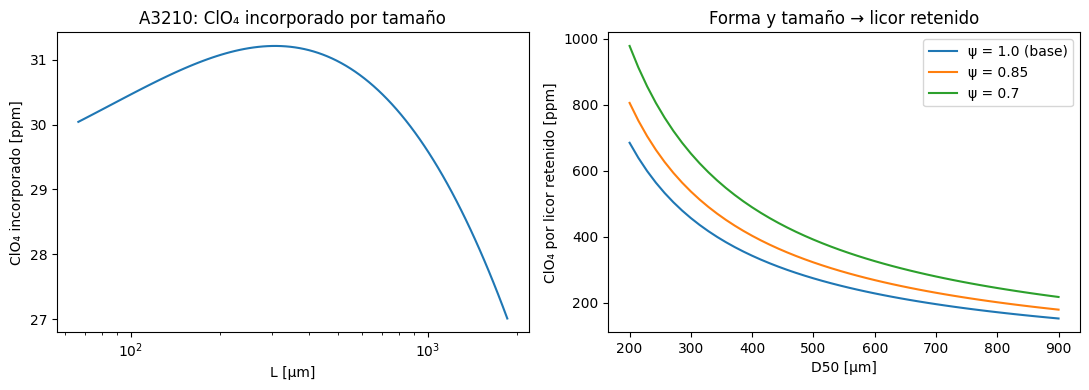

In [22]:
def evaluar(oper=OPER, kin=KIN, imp=IMP, f=None, y0=None, t_h=10.0):
    """Estado estacionario (partiendo de y0) e indicadores del tren."""
    y0 = y_ss if y0 is None else y0
    y = simular(t_h=t_h, oper=oper, kin=kin, imp=imp, f=f, y0=y0, n_out=2).y[:, -1]
    if deriva_maxima(y, oper, kin, imp, f) > 1e-4:          # todavía lejos del estacionario: se continúa
        y = simular(t_h=t_h, oper=oper, kin=kin, imp=imp, f=f, y0=y, n_out=2).y[:, -1]
    a1, a2 = resultados_tren(y, oper, kin, imp, f); p = ppm_producto(a2, imp, f)
    return {"KNO₃ producido [t/h]": a2["prod_t_h"], "D50 A3210 [µm]": a2["D50_um"],
            "finos < 100 µm [%]": a2["finos100_pct"], "ClO₄ crudo [ppm]": p["crudo"],
            "ClO₄ refinado esperado [ppm]": p["refinado esperado"], "KClO₄ coprecipitado [ppm]": p["coprecipitado"],
            "holgura KClO₄ A3210 [°C]": holgura_termica(oper["T_C"][2], a2["diag"]["comp"]),
            "evaporación total [t/h]": a1["evap_t_h"] + a2["evap_t_h"]}, y

# ClO4 incorporado por clase de tamaño (A3210) y efecto de la esfericidad sobre el licor retenido
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
msk = (r2["pasante"] > 0.1) & (r2["pasante"] < 99.9)
ax[0].plot(LC[msk] * 1e6, r2["ppm_clase"][msk])
ax[0].set(xscale="log", xlabel="L [µm]", ylabel="ClO₄ incorporado [ppm]", title="A3210: ClO₄ incorporado por tamaño")
for psi in (1.0, 0.85, 0.7):
    d = np.linspace(200, 900, 50)
    w = PROP["rho_liq"] * IMP["pelicula_m"] * sup_especifica(d * 1e-6, forma_granular(psi=psi))
    ax[1].plot(d, 1e6 * w * r2["diag"]["x_ClO4"], label=f"ψ = {psi}" + (" (base)" if psi == 1.0 else ""))
ax[1].set(xlabel="D50 [µm]", ylabel="ClO₄ por licor retenido [ppm]", title="Forma y tamaño → licor retenido")
ax[1].legend(); plt.tight_layout(); plt.show()

### 8.2 A3210 está en el borde de saturación del KClO₄ (y hay histéresis)

Con la termodinámica de las secciones 2 y 3, el licor de A3210 a 40 °C queda **sobresaturado en KClO₄** (σ ≈ 0,08, holgura negativa de alrededor de 2 °C). Es coherente con el ensayo de SQM, cuya inflexión está cerca de 40 °C sin evaporación: en el cristalizador, la evaporación concentra además el perclorato. Lo que hoy evita la precipitación es la **zona metaestable**.

El barrido siguiente baja la temperatura de A3210 desde 46 °C hasta 36 °C y luego la vuelve a subir, partiendo cada punto del anterior:

- **De bajada:** el KClO₄ no precipita mientras $\sigma_{KClO_4} < \sigma_{ZM}$. Al cruzar ese umbral, nuclea y el ClO₄ del crudo se dispara. Los cambios de temperatura son escalones de 1 °C: un escalón brusco puede producir un pico transitorio de $\sigma_{KClO_4}$ y adelantar la nucleación, algo que también puede ocurrir en planta.
- **De subida:** el KClO₄ ya formado **sigue creciendo mientras $\sigma_{KClO_4} > 0$**. Volver a 40 °C no basta: hay que subir hasta que la holgura sea positiva para redisolverlo.

**Lectura para SQM:** una baja transitoria de temperatura en A3210 puede dejar al cristalizador contaminando con KClO₄ aunque después vuelva a su consigna. Los valores exactos de los umbrales dependen de $\Gamma_{KClO_4}$ (un solo ensayo) y de $\sigma_{ZM}$ (cota inferida); lo robusto es el comportamiento.

,rama,T A3210 [°C],σ KClO₄,holgura KClO₄ A3210 [°C],KClO₄ coprecipitado [ppm],ClO₄ crudo [ppm],ClO₄ refinado esperado [ppm],KNO₃ producido [t/h]
0,bajada,46.0,-0.033,2.014,0.000,271.082,27.379,62.301
1,bajada,45.0,-0.014,0.876,0.000,272.834,27.556,65.999
2,bajada,44.0,0.005,-0.158,0.000,274.983,27.773,69.595
3,bajada,43.0,0.025,-0.711,0.000,277.323,28.010,73.088
4,bajada,42.0,0.044,-1.254,0.000,279.816,28.261,76.480
5,bajada,41.0,0.064,-1.789,0.000,282.432,28.526,79.773
6,bajada,40.0,0.018,-0.510,2161.472,2414.621,243.877,82.882
7,bajada,39.0,0.022,-0.614,2533.420,2781.994,280.981,85.963
8,bajada,38.0,0.026,-0.713,2867.927,3112.063,314.318,88.950
9,bajada,37.0,0.029,-0.808,3169.879,3409.703,344.380,91.846


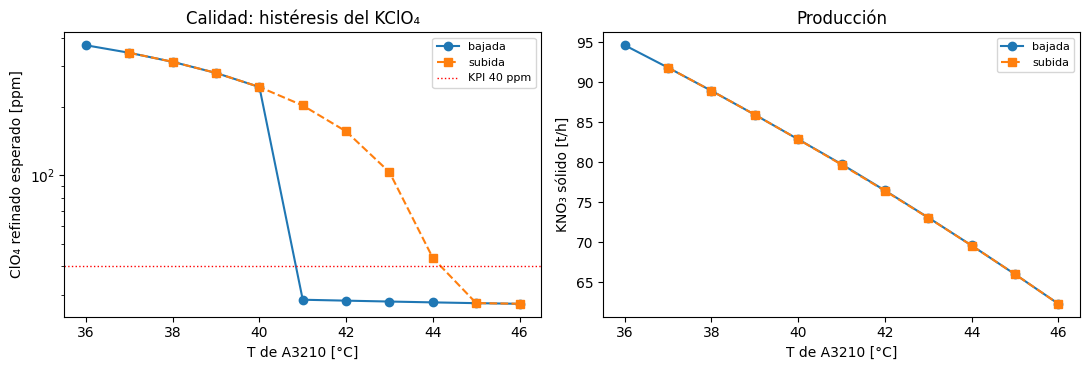

In [23]:
filas = []; y_prev = y_ss
for rama, Ts in (("bajada", np.arange(46.0, 35.9, -1.0)), ("subida", np.arange(37.0, 46.1, 1.0))):
    for T2 in Ts:
        op = copy.deepcopy(OPER); op["T_C"][2] = float(T2)
        res, y_prev = evaluar(op, y0=y_prev)
        a2 = resultados_tren(y_prev, oper=op)[1]
        filas.append({"rama": rama, "T A3210 [°C]": T2, "σ KClO₄": a2["diag"]["sigma_KClO4"], **res})
barrido_T2 = pd.DataFrame(filas)
display(barrido_T2[["rama", "T A3210 [°C]", "σ KClO₄", "holgura KClO₄ A3210 [°C]", "KClO₄ coprecipitado [ppm]",
                    "ClO₄ crudo [ppm]", "ClO₄ refinado esperado [ppm]", "KNO₃ producido [t/h]"]].round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for rama, mk in (("bajada", "o-"), ("subida", "s--")):
    d = barrido_T2[barrido_T2["rama"] == rama]
    ax[0].plot(d["T A3210 [°C]"], d["ClO₄ refinado esperado [ppm]"], mk, label=rama)
    ax[1].plot(d["T A3210 [°C]"], d["KNO₃ producido [t/h]"], mk, label=rama)
ax[0].axhline(HIST["KPI_refinado_ppm"], ls=":", c="r", lw=1, label="KPI 40 ppm")
ax[0].set(xlabel="T de A3210 [°C]", ylabel="ClO₄ refinado esperado [ppm]", yscale="log", title="Calidad: histéresis del KClO₄")
ax[1].set(xlabel="T de A3210 [°C]", ylabel="KNO₃ sólido [t/h]", title="Producción")
for a_ in ax: a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 8.3 Propuesta para SQM: incorporar la rugosidad del cristal

El modelo actual trata el licor adherido como una **película uniforme** sobre la superficie del cristal granular. Los cristales reales tienen rugosidad (cavidades, escalones, uniones entre cristales de un aglomerado) donde el licor madre queda retenido. Esta sección deja planteada la extensión del modelo. **No está implementada**: sus parámetros todavía no tienen datos.

**Por qué la rugosidad no se modela como más área.** Si las asperezas son más chicas que el espesor de la película (unos pocos µm), la película las cubre sin mojar más superficie. El efecto de la rugosidad es un **volumen adicional de licor retenido** que, además, se lava peor.

**Ecuaciones propuestas.** La superficie envolvente del cristal granular es

$$a_{env} = \frac{6}{\psi\,\rho_c\,L}$$

y el licor retenido por kg de cristal se reparte en dos compartimentos, película y cavidades:

$$w_{adh} = \rho_l\, a_{env}\,\big(\delta_f + \varepsilon_R\, h_R\big)$$

donde $\delta_f$ es el espesor de la película, $h_R$ la profundidad media de la rugosidad y $\varepsilon_R$ la fracción hueca de la capa rugosa. El perclorato que queda en el producto después del lavado es

$$\text{ppm}_{lav} = 10^6\, x_{ClO_4}\,\rho_l\, a_{env}\,\big[\delta_f\,(1-\eta_f) + \varepsilon_R h_R\,(1-\eta_R)\big]$$

- La película se desplaza con el agua de lavado, así que su eficiencia $\eta_f$ es alta.
- Las cavidades solo se vacían por **difusión**:
  $$\eta_R = 1 - \exp\!\left(-\frac{D(T)\, t_{lav}}{h_R^2}\right)$$
  El coeficiente de difusión $D$ aumenta con la temperatura porque baja la viscosidad del licor.

**Coherencia con los ensayos de lavado de SQM.** En el Compilado de pruebas, pasar de 75 a 100 L/min de agua de lavado no mejoró la remoción, y subir el agua a 40 °C sí la mejoró. Un modelo de una sola película no puede explicar las dos cosas a la vez. El de dos compartimentos sí: la meseta frente al caudal corresponde al licor de las cavidades, y la mejora con la temperatura es la firma de la difusión ($\eta_R$).

**Experimentos para obtener los parámetros** (planteados a nivel conceptual):

| Parámetro | Experimento | Qué se obtiene |
|---|---|---|
| $k_v$ | Pesar una fracción angosta de tamiz (por ejemplo 500–850 µm) y contar sus cristales | $k_v = m/(N\rho_c \bar L^3)$ |
| $\psi$ | Análisis de imágenes (área proyectada y perímetro) de unos 50 cristales por equipo | Esfericidad y superficie respecto de una esfera |
| $\delta_{eff} = \delta_f + \varepsilon_R h_R$ | Humedad de la torta centrifugada en dos o tres fracciones de tamiz | Pendiente de la humedad frente a $1/L$ |
| $\eta_f$, $\eta_R$ y la razón $\varepsilon_R h_R/\delta_f$ | Ensayos de lavado con distintos caudales de agua y dos temperaturas, midiendo ClO₄ en el cristal antes y después | Meseta (cavidades) y efecto de T (difusión) |
| $h_R$ | Imágenes de mayor aumento (lupa estereoscópica o SEM) | Verificación del orden de magnitud de la rugosidad |

Con estos parámetros, el modelo podría predecir cuánto perclorato se va con el lavado según la CSD, la forma y las condiciones de lavado. Eso conecta el cristalizador con el KPI del producto refinado (< 40 ppm).

### 8.4 Estado de la sección

| Ítem de la checklist | Estado |
|---|---|
| Mecanismos separados: licor retenido, inclusiones, coprecipitación | ✅ |
| Coeficiente de reparto dependiente de G | ✅ BPS + inclusiones; $k_{inc}$ anclado al crudo, $k_0$ y $n$ placeholders |
| ClO₄ en el cristal en ppm base seca | ✅ por etapa (crudo y refinado esperado) |
| ClO₄ por clase de tamaño | ✅ |
| Conexión con el lavado y el KPI del refinado (< 40 ppm) | ✅ con la eficiencia del área 6000; 🟡 el lavado en centrífuga queda dentro de los 0,070 kg/kg del balance |
| Rugosidad del cristal | 📋 propuesta para SQM (8.3) |

## 9. Equipo y control

### 9.1 Volumen de pulpa equivalente

El modelo fija el inventario en masa ($\tau\,\dot m_{in}$). Aquí se calcula el volumen de pulpa que eso implica y se compara con los 660 m³ usados en los modelos anteriores (valor no verificado para estos equipos).

In [24]:
for nombre, r, k in (("A3110", r1, 1), ("A3210", r2, 2)):
    print(f"{nombre}: inventario = {inventarios()[k]/1000:.0f} t, volumen de pulpa = {r['diag']['V']:.0f} m³ "
          f"(τ = {OPER['tau_h'][k]} h; referencia no verificada: 660 m³)")

A3110: inventario = 284 t, volumen de pulpa = 190 m³ (τ = 0.7 h; referencia no verificada: 660 m³)
A3210: inventario = 567 t, volumen de pulpa = 361 m³ (τ = 1.4 h; referencia no verificada: 660 m³)


### 9.2 Agua de dilución en el proceso completo (estado estacionario)

Es la variable manipulable de calidad. Se recorre entre 0 y 80 t/h (caso base: 27,14 t/h) con todo lo demás fijo. Cada punto parte del caso base, sin KClO₄ sólido. Las cruces rojas marcan los puntos donde el KClO₄ nucleó; en ellos la holgura se calcula con el licor ya empobrecido en perclorato, por eso no es monótona.

,agua de dilución [t/h],KNO₃ producido [t/h],D50 A3210 [µm],finos < 100 µm [%],ClO₄ crudo [ppm],ClO₄ refinado esperado [ppm],KClO₄ coprecipitado [ppm],holgura KClO₄ A3210 [°C],evaporación total [t/h]
0,0.00,100.31,509.86,0.47,3680.34,371.71,3400.90,-1.10,23.52
1,15.00,90.73,522.01,0.43,3043.05,307.35,2778.07,-0.75,22.79
2,27.14,82.97,537.33,0.43,285.33,28.82,0.00,-2.31,22.21
3,40.00,74.55,552.70,0.47,261.10,26.37,0.00,-1.27,21.56
4,60.00,61.34,555.29,0.52,237.51,23.99,0.00,0.55,20.43
5,80.00,48.05,549.99,0.54,219.33,22.15,0.00,3.33,19.23


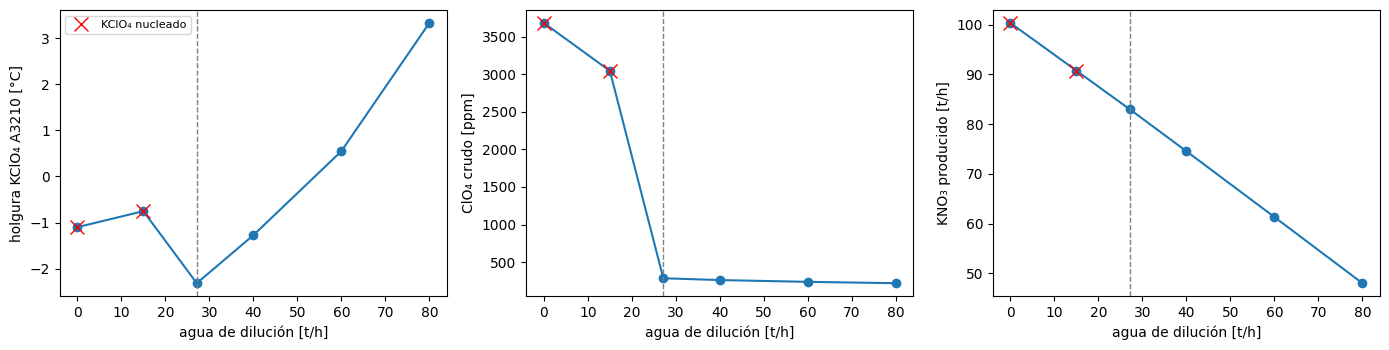

In [25]:
filas = []
for d in (0.0, 15.0, 27.14, 40.0, 60.0, 80.0):
    op = copy.deepcopy(OPER); op["F_dil_kg_s"] = d / 3.6
    res, _ = evaluar(op)                       # cada punto parte del caso base
    filas.append({"agua de dilución [t/h]": d, **res})
barrido_dil = pd.DataFrame(filas)
display(barrido_dil.round(2))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
nucl = barrido_dil["KClO₄ coprecipitado [ppm]"] > 1
for a, col in zip(ax, ("holgura KClO₄ A3210 [°C]", "ClO₄ crudo [ppm]", "KNO₃ producido [t/h]")):
    a.plot(barrido_dil["agua de dilución [t/h]"], barrido_dil[col], "o-")
    a.plot(barrido_dil["agua de dilución [t/h]"][nucl], barrido_dil[col][nucl], "rx", ms=10, label="KClO₄ nucleado")
    a.axvline(27.14, ls="--", c="0.5", lw=1); a.set(xlabel="agua de dilución [t/h]", ylabel=col)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 9.3 Respuesta dinámica a escalones

Como en el notebook evaporativo, se parte del estado estacionario y se aplica un escalón en una variable de operación. Se registra la trayectoria y el **tiempo al 63 %** del cambio total (constante de tiempo aparente), útil para sintonizar el lazo de dilución.

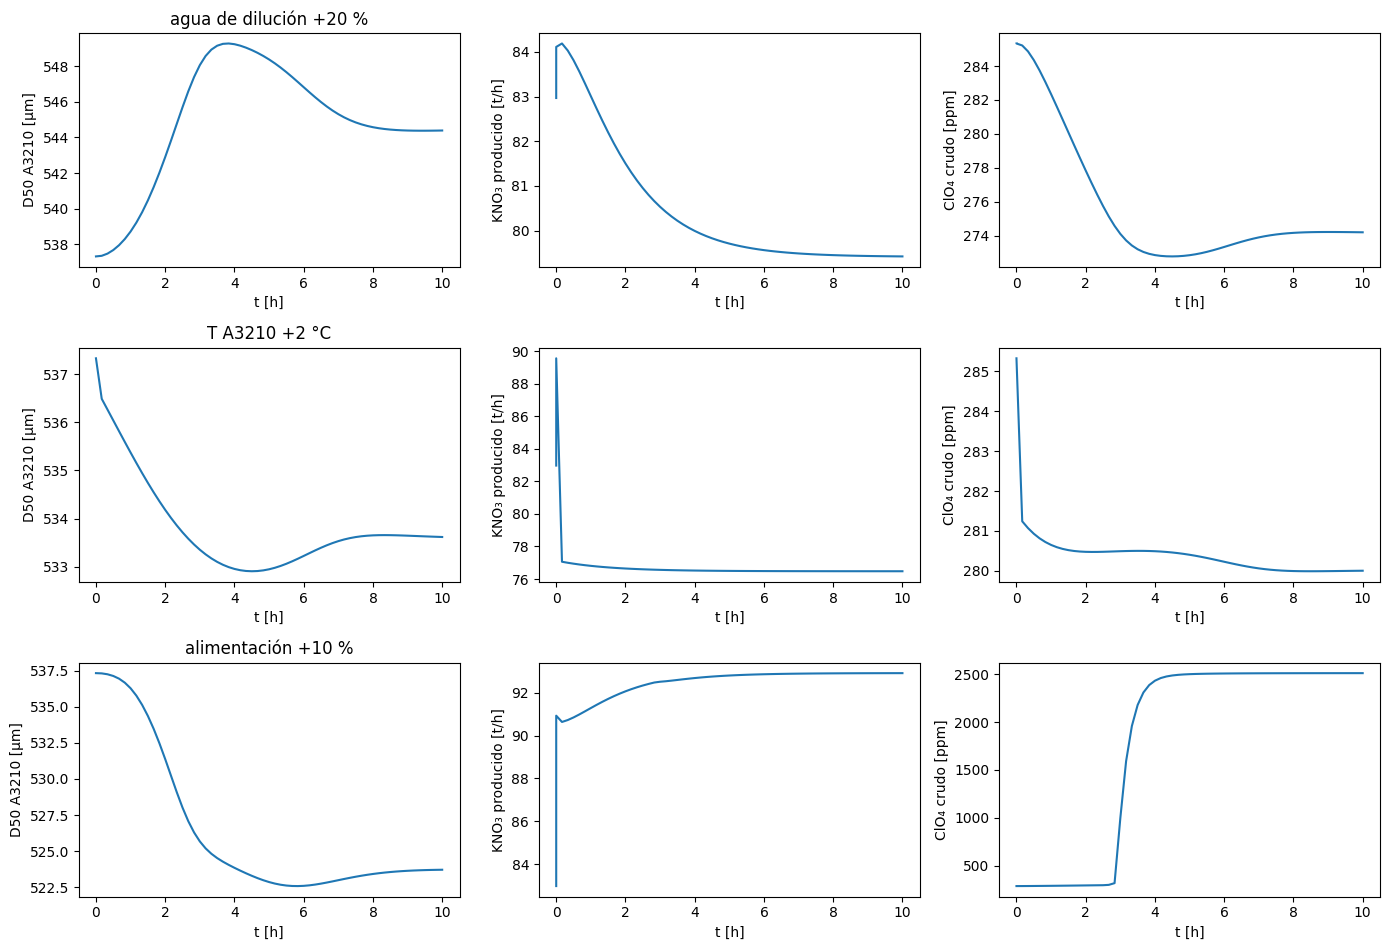

,escalón,salida,inicial,final,t al 63 % [h]
0,agua de dilución +20 %,D50 A3210 [µm],537.33,544.39,1.78
1,agua de dilución +20 %,KNO₃ producido [t/h],82.97,79.42,2.75
2,agua de dilución +20 %,ClO₄ crudo [ppm],285.33,274.20,1.90
3,T A3210 +2 °C,D50 A3210 [µm],537.33,533.62,1.30
4,T A3210 +2 °C,KNO₃ producido [t/h],82.97,76.48,0.14
5,T A3210 +2 °C,ClO₄ crudo [ppm],285.33,280.00,0.14
6,alimentación +10 %,D50 A3210 [µm],537.33,523.71,2.39
7,alimentación +10 %,KNO₃ producido [t/h],82.97,92.92,0.00
8,alimentación +10 %,ClO₄ crudo [ppm],285.33,2512.05,3.21


In [26]:
def t_fraccion(t, v, frac=0.632):
    cambio = v[-1] - v[0]
    if abs(cambio) < 1e-9 * max(abs(v[0]), 1): return np.nan
    nv = (v - v[0]) / cambio
    i = int(np.argmax(nv >= frac))
    if i == 0: return np.nan
    return t[i-1] + (frac - nv[i-1]) / (nv[i] - nv[i-1]) * (t[i] - t[i-1])

escalones = {"agua de dilución +20 %": ("F_dil_kg_s", 1.2), "T A3210 +2 °C": ("T2", 2.0), "alimentación +10 %": ("F_pre_kg_s", 1.1)}
fig, ax = plt.subplots(len(escalones), 3, figsize=(14, 3.2 * len(escalones)))
resumen = []
for fila, (nombre, (var, val)) in enumerate(escalones.items()):
    op = copy.deepcopy(OPER)
    if var == "T2": op["T_C"][2] += val
    else: op[var] *= val
    s = simular(t_h=10.0, oper=op, y0=y_ss, n_out=61); t = np.concatenate([[0.0], s.t / 3600])
    serie = {"D50 A3210 [µm]": [r2["D50_um"]], "KNO₃ producido [t/h]": [r2["prod_t_h"]],
             "ClO₄ crudo [ppm]": [ppm_producto(r2)["crudo"]]}          # valor justo antes del escalón
    for i in range(s.t.size):
        a2 = resultados_tren(s.y[:, i], oper=op)[1]
        serie["D50 A3210 [µm]"].append(a2["D50_um"]); serie["KNO₃ producido [t/h]"].append(a2["prod_t_h"])
        serie["ClO₄ crudo [ppm]"].append(ppm_producto(a2)["crudo"])
    for c, (k, v) in enumerate(serie.items()):
        v = np.array(v); ax[fila, c].plot(t, v); ax[fila, c].set(xlabel="t [h]", ylabel=k, title=nombre if c == 0 else "")
        resumen.append({"escalón": nombre, "salida": k, "inicial": v[0], "final": v[-1], "t al 63 % [h]": t_fraccion(t, v)})
plt.tight_layout(); plt.show()
display(pd.DataFrame(resumen).round(2))

### 9.4 Estado de la sección

| Ítem de la checklist | Estado |
|---|---|
| Volumen efectivo y tiempos de residencia | 🟡 τ del protocolo de la Entrega 2; volumen de pulpa calculado (9.1), falta verificar con SQM |
| Variables manipulables | ✅ agua de dilución, alimentación, T de cada etapa (vacío), τ (nivel) |
| Versión dinámica para el lazo de dilución | ✅ escalones y tiempo al 63 % (9.3); los lazos PID detallados siguen en `msmpr_core` |
| Reciclo de licor madre con purga | ❌ no incluido (el SSKd ya trae el licor reciclado); está en `msmpr_core` |
| Saturación del KClO₄ como restricción dura | 🟡 se usa como restricción en el frente de Pareto (sección 10); no está en un controlador |

## 10. Calibración y verificación

### 10.1 Calibración de la cinética con la granulometría de planta

**Qué se puede identificar con una granulometría.** En estado estacionario, la CSD depende de cuántos cristales nacen ($B$) y de cuánto crecen ($G\tau$). La sobresaturación $\sigma$ no se mide: se ajusta sola hasta que el consumo de soluto iguala lo que entra. Si se elimina $\sigma$ entre $G = k_g\sigma$ y $B_s = k_{bs}\sigma^2 M_T$, queda $B_s = (k_{bs}/k_g^{2})\, G^{2}\, M_T$. Es decir, **la CSD solo determina $\theta = \log_{10}(k_{bs}/k_g^2)$**, no $k_g$ y $k_{bs}$ por separado. Se calibran $\theta$ y $\gamma$; $k_g$ queda fijo y solo define el nivel de $\sigma$. Para separarlos hay que medir el KNO₃ en el licor madre.

El ajuste usa los 16 puntos (8 mallas × 2 equipos), ponderados por la desviación estándar entre los 21 tamizajes (piso de 1 punto porcentual). Es un **ajuste al promedio de agosto**: para validar hay que usar tamizajes de otro período. El resultado debe coincidir con `THETA_CAL` de la sección 1; si no, se actualiza ese valor.

In [27]:
_cache = {"y": None}
def kin_desde(p, kin_base=KIN):
    return dict(kin_base, kg=KG_REF, kbs=10 ** p[0] * KG_REF ** 2, gamma=p[1])

def residuos_calib(p):
    kin = kin_desde(p)
    try:
        sol_c = simular(t_h=12.0, kin=kin, y0=_cache["y"] if _cache["y"] is not None else y_ss, n_out=2)
    except RuntimeError:
        return 1e3 * np.ones(16)
    _cache["y"] = sol_c.y[:, -1]
    a1, a2 = resultados_tren(_cache["y"], kin=kin)
    return np.concatenate([(r["pasante_mallas"] - AG_PLANTA[k]["media"]) / np.maximum(AG_PLANTA[k]["sd"], 1.0)
                           for k, r in ((1, a1), (2, a2))])

t0 = time.time()
fit_kin = least_squares(residuos_calib, [THETA_CAL - 0.3, 0.0], bounds=([10, 0], [30, 5e3]),
                        x_scale=[1, 500], diff_step=1e-3, max_nfev=60)
print(f"Calibración: {time.time()-t0:.0f} s, {fit_kin.nfev} evaluaciones; chi² = {2*fit_kin.cost:.2f} con 16 datos y 2 parámetros")
libre = (fit_kin.x > np.array([10, 0]) + 1e-6) & (fit_kin.x < np.array([30, 5e3]) - 1e-6)
J = fit_kin.jac[:, libre]; s2 = 2 * fit_kin.cost / (16 - libre.sum())
sd = np.full(2, np.nan); sd[libre] = np.sqrt(np.diag(s2 * np.linalg.inv(J.T @ J)))
display(pd.DataFrame({"parámetro": ["theta = log10(kbs/kg²)", "gamma [1/m]"], "valor": fit_kin.x, "desv. est.": sd,
                      "estado": ["identificable" if l else "en el límite" for l in libre]}).round(3))
print(f"THETA_CAL (sección 1) = {THETA_CAL} | recalibrado = {fit_kin.x[0]:.3f} "
      f"({'coincide' if abs(fit_kin.x[0]-THETA_CAL) < 2*max(sd[0], 0.01) else 'ACTUALIZAR THETA_CAL'})")
if not libre[1]:
    print("gamma quedó en 0: la granulometría promedio no pide crecimiento dependiente del tamaño (ley de McCabe).")

Calibración: 60 s, 10 evaluaciones; chi² = 7.08 con 16 datos y 2 parámetros


,parámetro,valor,desv. est.,estado
0,theta = log10(kbs/kg²),19.059,0.067,identificable
1,gamma [1/m],0.000,NaN,en el límite


THETA_CAL (sección 1) = 19.058 | recalibrado = 19.059 (coincide)
gamma quedó en 0: la granulometría promedio no pide crecimiento dependiente del tamaño (ley de McCabe).


### 10.2 Sensibilidad de variables de operación

Se perturba una variable a la vez alrededor del caso base, como en el notebook de Pareto: agua de dilución y alimentación (±20 % y ±10 %), temperaturas (±2 °C) y tiempos de residencia (±20 %). Al cambiar la alimentación, el lazo de nivel mantiene el inventario y el tiempo de residencia efectivo cambia; al cambiar τ, cambia la consigna de nivel. El mapa muestra el cambio relativo de cada salida (%); la holgura se muestra como cambio absoluto en °C.

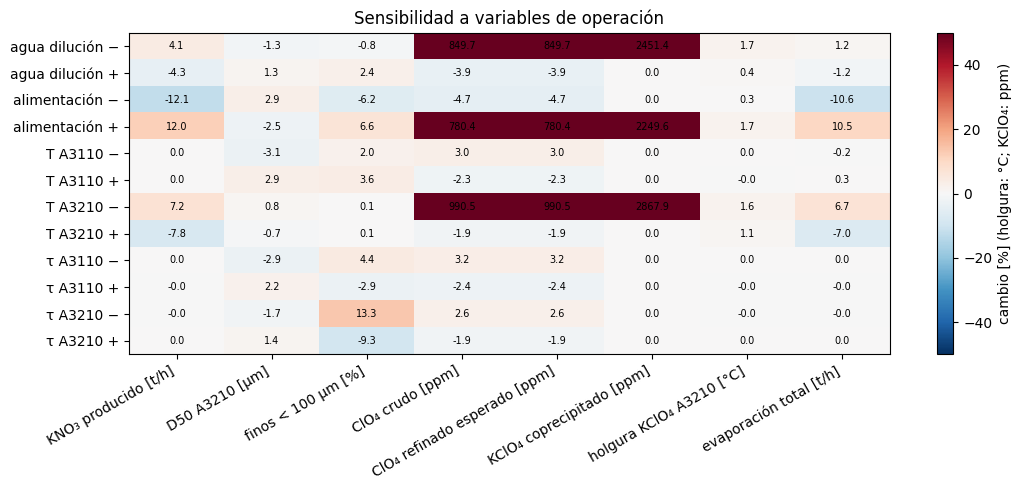

In [28]:
base_res, _ = evaluar()
pert = [("agua dilución", "F_dil_kg_s", 0.8, 1.2, "rel"), ("alimentación", "F_pre_kg_s", 0.9, 1.1, "rel"),
        ("T A3110", ("T_C", 1), -2.0, 2.0, "abs"), ("T A3210", ("T_C", 2), -2.0, 2.0, "abs"),
        ("τ A3110", ("tau_h", 1), 0.8, 1.2, "rel"), ("τ A3210", ("tau_h", 2), 0.8, 1.2, "rel")]
def aplicar(op, clave, v, modo):
    if isinstance(clave, tuple):
        op[clave[0]][clave[1]] = op[clave[0]][clave[1]] * v if modo == "rel" else op[clave[0]][clave[1]] + v
    else:
        op[clave] = op[clave] * v if modo == "rel" else op[clave] + v
    return op

salidas = list(base_res.keys())
filas = {}
for nombre, clave, lo, hi, modo in pert:
    for v, etiqueta in ((lo, "−"), (hi, "+")):
        res, _ = evaluar(aplicar(copy.deepcopy(OPER), clave, v, modo))
        filas[f"{nombre} {etiqueta}"] = {s: (res[s] - base_res[s]) if ("holgura" in s or "coprecipitado" in s) else 100 * (res[s] / base_res[s] - 1) for s in salidas}
sens_op = pd.DataFrame(filas).T
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(np.clip(sens_op.values, -50, 50), cmap="RdBu_r", vmin=-50, vmax=50, aspect="auto")
ax.set_xticks(range(len(salidas)), salidas, rotation=30, ha="right"); ax.set_yticks(range(len(sens_op)), sens_op.index)
for i in range(sens_op.shape[0]):
    for j in range(sens_op.shape[1]):
        ax.text(j, i, f"{sens_op.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="cambio [%] (holgura: °C; KClO₄: ppm)"); ax.set_title("Sensibilidad a variables de operación")
plt.tight_layout(); plt.show()

### 10.3 Elasticidades de parámetros constitutivos

Elasticidad por diferencia central: $E = \dfrac{y(p(1+h)) - y(p(1-h))}{2h\,y_{base}}$ con $h = 0{,}1$. Para $\theta$ (logarítmico) y $\ln\Gamma$ se perturba en valor absoluto (±0,1) y se informa el cambio relativo de la salida por unidad. Para $\psi$, que no puede superar 1, se usa una diferencia hacia atrás.

**Cuidado al leer las filas de $\ln\Gamma_{KClO_4}$ y $\sigma_{ZM}$:** el caso base está cerca del umbral de nucleación del KClO₄ (σ_ZM es apenas 10 % mayor que la σ del caso base). Una perturbación que cruza el umbral hace nuclear al KClO₄ y el ClO₄ del crudo salta en un orden de magnitud. Esas elasticidades enormes no son una derivada suave: indican que **la calidad del producto es muy sensible a la termodinámica del KClO₄ y al ancho de la zona metaestable**, que son justamente los datos más inciertos.

In [29]:
def con_param(nombre, factor):
    """Devuelve (kin, imp, f) con el parámetro perturbado; TERMO se modifica en el lugar (se restaura después)."""
    kin, imp, f = dict(KIN), dict(IMP), dict(FORMA)
    if nombre == "theta":   kin["kbs"] = KIN["kbs"] * 10 ** factor
    elif nombre in ("bs", "j", "g"): kin[nombre] = KIN[nombre] * factor
    elif nombre == "lnGamma_KClO4": TERMO["lnGamma0"]["KClO4"] = LNG0 + factor
    elif nombre == "kv":    f = forma_granular(FORMA["kv"] * factor, FORMA["psi"])
    elif nombre == "psi":   f = forma_granular(FORMA["kv"], FORMA["psi"] * factor)
    elif nombre in ("kinc", "k0", "sigmaZM_KClO4", "pelicula_m"): imp[nombre] = IMP[nombre] * factor
    return kin, imp, f

LNG0 = TERMO["lnGamma0"]["KClO4"]
params = [("theta", -0.1, 0.1, 0.1), ("bs", 0.9, 1.1, 0.1), ("j", 0.9, 1.1, 0.1),
          ("lnGamma_KClO4", -0.1, 0.1, 0.1), ("kv", 0.9, 1.1, 0.1), ("psi", 0.9, 1.0, 0.05),
          ("kinc", 0.9, 1.1, 0.1), ("k0", 0.9, 1.1, 0.1), ("sigmaZM_KClO4", 0.9, 1.1, 0.1), ("pelicula_m", 0.9, 1.1, 0.1)]
elast = {}
for nombre, lo, hi, h in params:
    ys = []
    for v in (lo, hi):
        kin, imp, f = con_param(nombre, v)
        res, _ = evaluar(kin=kin, imp=imp, f=f)
        TERMO["lnGamma0"]["KClO4"] = LNG0
        ys.append(res)
    den = (hi - lo) if nombre in ("theta", "lnGamma_KClO4") else (hi - lo)
    elast[nombre] = {s: ((ys[1][s] - ys[0][s]) / den) if ("holgura" in s or "coprecipitado" in s) else (ys[1][s] - ys[0][s]) / (den * base_res[s])
                     for s in salidas}
elast = pd.DataFrame(elast).T
display(elast.round(3))
print("Filas theta y lnGamma: cambio relativo por unidad del parámetro. Holgura (°C) y KClO₄ coprecipitado (ppm): cambio absoluto por unidad.")

,KNO₃ producido [t/h],D50 A3210 [µm],finos < 100 µm [%],ClO₄ crudo [ppm],ClO₄ refinado esperado [ppm],KClO₄ coprecipitado [ppm],holgura KClO₄ A3210 [°C],evaporación total [t/h]
theta,0.001,-0.469,1.669,0.383,0.383,0.000,0.003,0.000
bs,-0.005,2.350,-10.000,-2.062,-2.062,0.000,-0.017,-0.002
j,0.002,-1.050,4.061,0.879,0.879,0.000,0.008,0.001
lnGamma_KClO4,0.008,0.001,0.000,-58.878,-58.878,-17052.198,-0.449,0.004
kv,0.002,-0.204,0.722,0.165,0.165,0.000,0.001,0.000
psi,0.000,0.000,0.000,-0.992,-0.992,0.000,0.000,0.000
kinc,0.000,-0.000,0.000,0.081,0.081,0.000,0.026,0.000
k0,0.000,-0.000,0.000,0.024,0.024,0.000,0.008,0.000
sigmaZM_KClO4,0.005,0.000,0.000,-37.316,-37.316,-10807.499,-9.019,0.003
pelicula_m,0.000,0.000,0.000,0.893,0.893,0.000,0.000,0.000


Filas theta y lnGamma: cambio relativo por unidad del parámetro. Holgura (°C) y KClO₄ coprecipitado (ppm): cambio absoluto por unidad.


### 10.4 Frente de Pareto: producción frente a calidad

Se busca **maximizar la producción de KNO₃ y minimizar el ClO₄ del refinado esperado**, variando el agua de dilución y la temperatura de A3210 en una malla determinista. A domina a B si produce al menos lo mismo con a lo sumo las mismas ppm y mejora en algo. Se marcan además los puntos que cumplen la **restricción dura** de holgura del KClO₄ ≥ 0 en A3210 y el KPI de 40 ppm.

Las ppm dependen de parámetros anclados a un solo dato (crudo) y de la cota de zona metaestable. El frente muestra **dónde está el compromiso**; los valores exactos se afinan cuando lleguen los datos de muestreo.

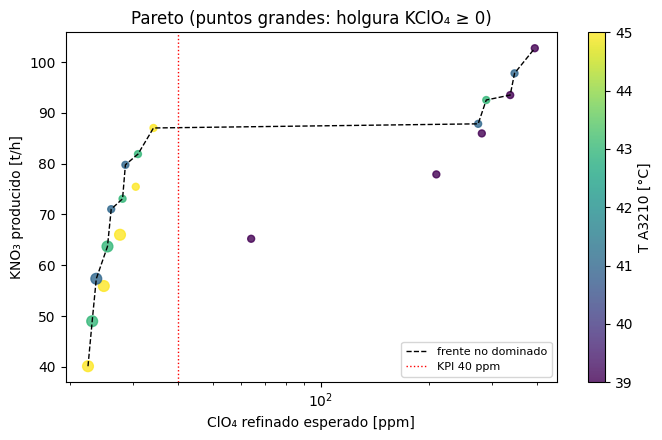

,agua de dilución [t/h],T A3210 [°C],KNO₃ producido [t/h],ClO₄ refinado esperado [ppm],holgura KClO₄ A3210 [°C],D50 A3210 [µm]
19,60.00,45.0,40.11,22.45,6.19,553.49
18,60.00,43.0,48.97,23.06,3.93,554.31
17,60.00,41.0,57.34,23.68,1.67,554.99
14,40.00,43.0,63.69,25.44,0.82,550.16
13,40.00,41.0,71.04,26.06,-0.74,551.95
10,27.14,43.0,73.09,28.03,-0.71,531.40
9,27.14,41.0,79.77,28.54,-1.79,535.58
6,15.00,43.0,81.89,30.94,-1.80,515.40
3,0.00,45.0,87.03,34.18,-2.22,502.35
5,15.00,41.0,87.85,274.46,-0.65,519.96


In [30]:
dil_grid = [0.0, 15.0, 27.14, 40.0, 60.0]
T2_grid = [39.0, 41.0, 43.0, 45.0]
puntos = []
for d in dil_grid:
    for T2 in T2_grid:
        op = copy.deepcopy(OPER); op["F_dil_kg_s"] = d / 3.6; op["T_C"][2] = T2
        res, _ = evaluar(op)                   # cada punto parte del caso base (sin KClO4 sólido)
        puntos.append({"agua de dilución [t/h]": d, "T A3210 [°C]": T2, **res})
pareto = pd.DataFrame(puntos)

def no_dominados(prod, ppm):
    nd = np.ones(len(prod), dtype=bool)
    for i in range(len(prod)):
        nd[i] = not np.any((prod >= prod[i]) & (ppm <= ppm[i]) & ((prod > prod[i]) | (ppm < ppm[i])))
    return nd
pareto["no dominado"] = no_dominados(pareto["KNO₃ producido [t/h]"].values, pareto["ClO₄ refinado esperado [ppm]"].values)
pareto["holgura ≥ 0"] = pareto["holgura KClO₄ A3210 [°C]"] >= 0
pareto["cumple 40 ppm"] = pareto["ClO₄ refinado esperado [ppm]"] < HIST["KPI_refinado_ppm"]

fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(pareto["ClO₄ refinado esperado [ppm]"], pareto["KNO₃ producido [t/h]"], c=pareto["T A3210 [°C]"],
                marker="o", s=np.where(pareto["holgura ≥ 0"], 60, 25), cmap="viridis", alpha=0.8)
fr = pareto[pareto["no dominado"]].sort_values("ClO₄ refinado esperado [ppm]")
ax.plot(fr["ClO₄ refinado esperado [ppm]"], fr["KNO₃ producido [t/h]"], "k--", lw=1, label="frente no dominado")
ax.axvline(HIST["KPI_refinado_ppm"], c="r", lw=1, ls=":", label="KPI 40 ppm")
ax.set(xscale="log", xlabel="ClO₄ refinado esperado [ppm]", ylabel="KNO₃ producido [t/h]",
       title="Pareto (puntos grandes: holgura KClO₄ ≥ 0)")
plt.colorbar(sc, label="T A3210 [°C]"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
display(fr[["agua de dilución [t/h]", "T A3210 [°C]", "KNO₃ producido [t/h]", "ClO₄ refinado esperado [ppm]",
            "holgura KClO₄ A3210 [°C]", "D50 A3210 [µm]"]].round(2))

### 10.5 Verificaciones numéricas

1. **Malla doble:** se repite el caso base con el doble de clases (360) y se exige un cambio menor al 4 % en producción, D50 y ClO₄ del crudo (mismo criterio del notebook de Pareto).
2. **Casos límite:** (a) sin ClO₄ en la alimentación, todo el perclorato del producto debe ser 0; (b) sin nucleación ni cristales, el modelo debe reducirse a un flash: el agua evaporada sale solo del calor sensible.

In [31]:
# (1) Malla doble
n0 = NCLASES
res_n, _ = evaluar()
set_malla(2 * n0)
res_2n, _ = evaluar(y0=simular(t_h=25.0, n_out=2).y[:, -1])
set_malla(n0)
malla = pd.DataFrame({f"{n0} clases": res_n, f"{2*n0} clases": res_2n})
malla["cambio"] = [(b - a) if ("holgura" in k or "coprecipitado" in k) else 100 * (b / a - 1)
                   for k, a, b in zip(malla.index, malla.iloc[:, 0], malla.iloc[:, 1])]
display(malla.round(3))
print("(cambio en %, salvo la holgura, en °C, y el KClO₄ coprecipitado, en ppm)")
ok = malla.loc[["KNO₃ producido [t/h]", "D50 A3210 [µm]", "ClO₄ crudo [ppm]"], "cambio"].abs().max() < 4
print("Malla doble:", "APROBADA (< 4 %)" if ok else "REVISAR")

# (2a) Sin perclorato en la alimentación
feed0 = dict(FEED, ClO4=1e-12)
_ent = entrada_SSKd
entrada_SSKd = lambda oper=OPER, feed=feed0, f=None: _ent(oper, feed, f)
y_a = simular(t_h=25.0, n_out=2).y[:, -1]            # arranque sin ClO4 en el licor ni en la alimentación
p_a = ppm_producto(resultados_tren(y_a)[1])
entrada_SSKd = _ent
print(f"(a) Sin ClO4 en la alimentación: crudo = {p_a['crudo']:.2e} ppm (esperado ~0)")

# (2b) Sin nucleación ni cristales: flash puro
kin0 = dict(KIN, kbp=0.0, kbs=0.0)
y_b = simular(t_h=12.0, kin=kin0, y0=estado_inicial(siembra=0.0), n_out=2).y[:, -1]
b1, _ = resultados_tren(y_b, kin=kin0)
e = entrada_SSKd(); m_in = e["W"] + e["I"] + sum(e[s] * M[s] / 1000 for s in ("K", "NO3", "ClO4", "Mg"))
evap_teo = m_in * PROP["cp_liq"] * (OPER["T_feed_C"] - OPER["T_C"][1]) / lambda_agua(OPER["T_C"][1])
print(f"(b) Flash sin cristales A3110: evaporación modelo = {b1['evap_t_h']:.3f} t/h | teórica = {3.6*evap_teo:.3f} t/h | "
      f"sólidos = {b1['solidos_pct']:.1e} %")

,180 clases,360 clases,cambio
KNO₃ producido [t/h],82.968,82.967,-0.002
D50 A3210 [µm],537.327,526.806,-1.958
finos < 100 µm [%],0.434,0.442,1.767
ClO₄ crudo [ppm],285.329,290.670,1.872
ClO₄ refinado esperado [ppm],28.818,29.358,1.872
KClO₄ coprecipitado [ppm],0.000,0.000,0.000
holgura KClO₄ A3210 [°C],-2.314,-2.314,-0.000
evaporación total [t/h],22.206,22.205,-0.001


(cambio en %, salvo la holgura, en °C, y el KClO₄ coprecipitado, en ppm)
Malla doble: APROBADA (< 4 %)
(a) Sin ClO4 en la alimentación: crudo = 4.21e-09 ppm (esperado ~0)
(b) Flash sin cristales A3110: evaporación modelo = 5.764 t/h | teórica = 5.764 t/h | sólidos = -1.9e-11 %


### 10.6 Exportación de resultados

Las tablas principales se guardan en una **carpeta nueva** junto al notebook (`resultados_Cristalizador_SQM/<fecha_hora>/`), sin sobrescribir ejecuciones anteriores.

In [32]:
carpeta = os.path.join("resultados_Cristalizador_SQM", datetime.datetime.now().strftime("%Y%m%d_%H%M%S"))
os.makedirs(carpeta, exist_ok=True)
tablas = {"caso_base_perclorato": pd.DataFrame(tabla), "barrido_T_A3210": barrido_T2, "barrido_dilucion": barrido_dil,
          "sensibilidad_operacion": sens_op, "elasticidades_parametros": elast, "pareto": pareto, "malla_doble": malla}
for nombre, df in tablas.items():
    df.to_csv(os.path.join(carpeta, f"{nombre}.csv"), encoding="utf-8-sig")
print(f"{len(tablas)} tablas guardadas en {carpeta}")

7 tablas guardadas en resultados_Cristalizador_SQM\20261116_114439


### 10.7 Estado de la sección

| Ítem de la checklist | Estado |
|---|---|
| Calibrar cinética y perclorato con datos reales | ✅ cinética con 21 tamizajes por equipo (θ); 🟡 perclorato anclado a un solo dato (mediana de crudo) |
| Datos de muestreo (CSD, ClO₄ sin lavar, MLK, fotos) | ❌ solicitud en curso |
| Sensibilidad de parámetros y de variables de operación | ✅ 10.2 y 10.3 |
| Frente de Pareto | ✅ 10.4 (con restricción de holgura y KPI) |
| Pruebas de balance y estacionario | ✅ secciones 5 y 6 |
| Casos límite | ✅ 10.5 |
| Malla doble | ✅ 10.5 |

## 11. Integración y documentación

### 11.1 Rango de validez

| Variable | Rango en que el modelo tiene respaldo | Origen |
|---|---|---|
| T de operación | 40–55 °C (cinética); 25–74 °C (solubilidad del KClO₄ en SSKd) | tamizajes de agosto 2026; ensayo de SQM |
| Composición del licor | Medianas del SSKd (oct-2026), Mg ≈ 27–29 g/L | AQ SSKd |
| Agua de dilución | 0–80 t/h (extrapolación del efecto termodinámico) | balance v6 (caso base 27,14 t/h) |
| Flujos y τ | ±20 % del caso base | protocolo Entrega 2 |
| Forma | Cristales equidimensionales (granulares) | fotos del Compilado |
| ClO₄ | Cerca de la mediana del crudo (202 ppm) | histórico de laboratorio |

Fuera de esos rangos, el modelo **extrapola**: las tendencias pueden ser útiles, pero los valores no tienen respaldo.

### 11.2 Procedencia de los parámetros

In [33]:
procedencia = pd.DataFrame([
    ("Curva KNO3–agua", "tabla BOC Sciences (coincide con CRC)", "citar CRC en el informe"),
    ("Curva KClO4–agua", "tabla BOC Sciences (coincide con CRC)", "citar CRC en el informe"),
    ("Γ_KClO4", "calibrado (ensayo SQM)", f"ln Γ = {TERMO['lnGamma0']['KClO4']:.3f}"),
    ("Γ_KNO3, k_Mg", "pendiente", "MLK y segundo ensayo de Mg"),
    ("θ = log10(kbs/kg²)", "calibrado (21 tamizajes × 2 equipos)", f"{THETA_CAL}"),
    ("γ (crecimiento según tamaño)", "calibrado", "0 (en el límite)"),
    ("Exponentes g, b_s, j, b_p", "bibliografía típica (fijos)", "1, 2, 1, 5"),
    ("k_v, ψ", "supuesto (forma granular)", "π/6, 1; medir"),
    ("k_inc", "estimado: crudo histórico − licor retenido con MLK histórico", f"{IMP['kinc']:.3e}"),
    ("k_0, δ/D, n", "placeholder", "medir ClO4 sin lavar por equipo"),
    ("σ_ZM del KClO4", "cota inferior inferida del histórico (sin KClO4 masivo)", f"{IMP['sigmaZM_KClO4']}"),
    ("δ_eff (licor retenido)", "anclado a 0,070 kg/kg (balance v6)", f"{IMP['pelicula_m']*1e6:.2f} µm"),
    ("η refinación (área 6000)", "Compilado pruebas A6000", f"{HIST['eta_refinacion']}"),
    ("τ_1, τ_2", "protocolo Entrega 2", "0,7 h / 1,4 h"),
], columns=["parámetro", "procedencia", "valor / pendiente"])
display(procedencia)

,parámetro,procedencia,valor / pendiente
0,Curva KNO3–agua,tabla BOC Sciences (coincide con CRC),citar CRC en el informe
1,Curva KClO4–agua,tabla BOC Sciences (coincide con CRC),citar CRC en el informe
2,Γ_KClO4,calibrado (ensayo SQM),ln Γ = 1.571
3,"Γ_KNO3, k_Mg",pendiente,MLK y segundo ensayo de Mg
4,θ = log10(kbs/kg²),calibrado (21 tamizajes × 2 equipos),19.058
5,γ (crecimiento según tamaño),calibrado,0 (en el límite)
6,"Exponentes g, b_s, j, b_p",bibliografía típica (fijos),"1, 2, 1, 5"
7,"k_v, ψ",supuesto (forma granular),"π/6, 1; medir"
8,k_inc,estimado: crudo histórico − licor retenido con...,2.656e-03
9,"k_0, δ/D, n",placeholder,medir ClO4 sin lavar por equipo


### 11.3 Estado frente a la checklist y pendientes

| Sección de la checklist | Cubierto | Pendiente principal |
|---|---|---|
| Termodinámica del KNO₃ | Apelblat + ion común + Γ; sobresaturación única; ΔH_c | $\Gamma_{KNO_3}$ con el MLK; Cp y densidad variables; Pitzer |
| Perclorato y magnesio | Ksp(T) con ion común, ensayo SQM reproducido, NaNO₃, dilución, holgura | $k_{Mg}$ (segundo ensayo) |
| Modo evaporativo | Balance de energía, dos etapas, semillas en la alimentación | BPE según composición; condensadores |
| Balances | K, NO₃, ClO₄, Mg, agua, inertes; cierre ~10⁻⁵ | Na⁺ y Cl⁻ por separado (no medidos en el SSKd) |
| Cinética y PBE | Nucleación primaria y secundaria, G(L), disolución, Gibbs–Thomson | Aglomeración/atrición; clasificación del DTB |
| Forma | Granular ($k_v$, ψ), prisma para sensibilidad | Medir $k_v$ y ψ |
| Perclorato en el cristal | Tres mecanismos, por tamaño, crudo y refinado esperado | ClO₄ sin lavar por equipo; rugosidad (propuesta 8.3) |
| Equipo y control | Volumen equivalente, dilución, escalones | Reciclo con purga y PID (en `msmpr_core`); restricción en el controlador |
| Calibración y verificación | θ calibrado, sensibilidades, Pareto, malla doble, casos límite, exportación | Validación con otro período |

**Diferencias con planta que siguen abiertas:** el % de sólidos de A3110 (modelo ≈ 6 % frente a ≈ 13 % de la Entrega 2) depende de $\Gamma_{KNO_3}$, sin calibrar. Los finos bajo 100 µm salen menores que en planta (< 1 % frente a ≈ 4 %), lo esperable sin atrición ni aglomeración. El ClO₄ del licor madre sale más alto que el histórico del MLK (≈ 5,3 g/L frente a 3,6 g/L), lo que también afecta la holgura del KClO₄: conviene revisarlo con el análisis del MLK que se pidió en el muestreo.

**Datos que destraban lo pendiente:** ClO₄ en cristal **sin lavar** por equipo, $k_v$ y ψ medidos, humedad de la torta, composición completa del MLK, un segundo ensayo de saturación a otro nivel de Mg y tamizajes de otro período para validar.